# Explore the metadata

**Question:** how was the screen set up, and what do the plate layout, the imaging records and the cell counts tell us before we look at the profiles?

We show where each control, ligand and compound (and its dose) sits on the plate, how the plates were imaged, and how many cells each well holds. Cell number gets the most room, because it matters in two ways: a treatment that kills cells or stops their growth is a result in itself, and the number of cells also changes how cells look (crowded cells are smaller and rounder), so a treatment can look "active" only because it changed the density.

Sections: 1. load the well tables, 2. screen design, 3. imaging, 4. cell counts on the plates, 5. DMSO control wells, 6. do treatments change cell number?, 7. how cell count relates to the profiles.

Terms used below:
- **Field of view:** one position imaged in a well (9 per well, in a 3 × 3 grid), each imaged in 5 channels.
- **All cells:** every cell found in the 9 fields of view of a well, before quality control (QC).
- **QC-passing cells:** cells that passed both image QC (sharp, not saturated) and profile QC (no segmentation errors). The well profiles are the median of these cells.
- **log2 ratio:** log2(cells in the well / median cells in the DMSO wells of the same plate and cell line). 0 = like DMSO, -1 = half as many cells, +1 = twice as many.

## Setup


In [1]:
import os

# limit threads, because this runs on a shared login node
os.environ["POLARS_MAX_THREADS"] = "8"
os.environ["OMP_NUM_THREADS"] = "8"
os.environ["NUMBA_NUM_THREADS"] = "8"
os.environ["OPENBLAS_NUM_THREADS"] = "8"
os.environ["MKL_NUM_THREADS"] = "8"

import json
import pathlib

import matplotlib.pyplot as plt
import numpy as np
import polars as pl
import seaborn as sns
import matplotlib.colors as mcolors
from matplotlib.colors import LinearSegmentedColormap, Normalize, TwoSlopeNorm
from matplotlib.lines import Line2D
from matplotlib.patches import Patch, Rectangle
from scipy import stats

In [2]:
# inputs: well profiles from the preprocessing module, single-cell QC labels, the layout files, and the imaging records
preprocess_results = pathlib.Path("../2.preprocessing/results")
all_cells_path = (preprocess_results / "agg_norm_fs_Panc1_hPSC_well-profiles.parquet").resolve(strict=True)
qced_path = (preprocess_results / "qced_agg_norm_fs_Panc1_hPSC_well-profiles.parquet").resolve(strict=True)
sc_qc_path = pathlib.Path("../1.quality-control/results/qc_Panc1_hPSC_sc-profiles.parquet").resolve(strict=True)
metadata_dir = pathlib.Path("../../data/metadata").resolve(strict=True)
# one folder per plate, with the microscope settings (parameters.json) and the position and time of every image (coords.jsonl)
imaging_dir = pathlib.Path("../../data/sc-profiles/PALS-screen-profiles-v2").resolve(strict=True)

# outputs
fig_dir = pathlib.Path("results/figures/02.explore-metadata").resolve()
table_dir = pathlib.Path("results/tables/02.explore-metadata").resolve()
fig_dir.mkdir(parents=True, exist_ok=True)
table_dir.mkdir(parents=True, exist_ok=True)

seed = 0
# values beyond this many MADs from DMSO are set to the limit, so a few extreme features cannot dominate distances
clip_limit = 20
# random draws of 3 DMSO wells used as the "no effect" reference for a treatment with 3 replicate wells (fixed order + seed, so results repeat exactly)
n_null_draws = 100_000
# false discovery rate used to call a treatment different from DMSO
fdr_threshold = 0.05
# a feature "strongly tracks cell count" when |Spearman rho| is at least this
strong_rho = 0.5
# a treatment is a possible toxic hit (same rule as mantispy.tl.cytotoxicity) below this share of DMSO cells
min_viability = 0.7

# fixed order and colors: the same as in the other notebooks
plate_order = ["1h", "4h", "24h"]
line_order = ["CL1", "CL2"]
line_colors = {"CL1": "#6250d6", "CL2": "#eda100"}
plate_colors = {"1h": "#2a78d6", "4h": "#eb6834", "24h": "#1baf7a"}
well_type_colors = {"control": "#a5a5a5", "compound": "#1baf7a", "ligand": "#d03b3b"}
# one color per agent, the same as in the UMAP notebook
agent_colors = {
    "DMSO": "#e3e3e3", "CBK041498": "#2a78d6", "CBK175924": "#eb6834", "CBK200566": "#1baf7a",
    "CBK600005": "#6250d6", "CBK600008": "#eda100", "IL6": "#d03b3b", "TGFb1": "#0d366b",
}
# laser line of each channel and the stain it images (from the image file names)
channel_stain = {"405": "DNA", "488": "RNA", "561": "AGP", "638": "Mito", "730": "ER"}
seq_cmap = LinearSegmentedColormap.from_list("blues", ["#cde2fb", "#2a78d6", "#0d366b"])
div_cmap = plt.get_cmap("RdBu_r")

# plate geometry
plate_rows = list("ABCDEFGHIJKLMNOP")
n_rows, n_cols = 16, 24
corner_wells = ["A01", "A24", "P01", "P24"]

# treatment order for tables and heatmaps: ligands first (TGFb1 = positive control), then compounds
compounds = ["CBK041498", "CBK175924", "CBK200566", "CBK600005", "CBK600008"]
treatment_order = ["TGFb1", "IL6", *compounds]
dose_order = {"ligand": ["L", "M", "H"], "compound": ["0.2", "0.67", "2.0"]}
dose_level = {"L": 0, "M": 1, "H": 2, "0.2": 0, "0.67": 1, "2.0": 2}
# what the dose labels mean: compound stock concentration, or final ligand concentration
dose_text = {"0.2": "0.2 mM", "0.67": "0.67 mM", "2.0": "2 mM", "L": "2.5 ng/ml", "M": "5 ng/ml", "H": "10 ng/ml"}
perturbation_order = [f"{t}_{d}" for t in ["TGFb1", "IL6"] for d in dose_order["ligand"]] + [
    f"{c}_{d}" for c in compounds for d in dose_order["compound"]
]

sns.set_theme(style="ticks", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
rng = np.random.default_rng(seed)


def save_fig(fig, name):
    """Save a figure as png for the report and show it in the notebook."""
    fig.savefig(fig_dir / f"{name}.png", dpi=200, bbox_inches="tight")
    plt.show()


def plate_array(df, value):
    """Arrange one value per well into a 16 x 24 plate grid (NaN where there is no well)."""
    grid = np.full((n_rows, n_cols), np.nan)
    grid[df["row_idx"].to_numpy(), df["col_idx"].to_numpy()] = df[value].to_numpy()
    return grid


def draw_plate(ax, grid, cmap, norm, title, treated=None, flagged=None):
    """Draw one plate heatmap, with the CL1 | CL2 split, crossed-out corners, and optional dots on treated wells."""
    cmap = cmap.copy()
    cmap.set_bad("#f0f0f0")
    im = ax.imshow(grid, cmap=cmap, norm=norm, aspect="equal", interpolation="none")
    ax.axvline(11.5, color="black", lw=2.5)
    ax.set_xticks(range(n_cols), labels=[str(i) for i in range(1, n_cols + 1)], fontsize=7)
    ax.set_yticks(range(n_rows), labels=plate_rows, fontsize=7)
    ax.tick_params(length=0, labeltop=False)
    for spine in ax.spines.values():
        spine.set_visible(False)
    for r, c in [(0, 0), (0, 23), (15, 0), (15, 23)]:
        ax.text(c, r, "×", ha="center", va="center", fontsize=8, color="#888888")
    if treated is not None:
        r, c = np.nonzero(treated)
        ax.scatter(c, r, s=3, color="black", marker="o", linewidths=0)
    if flagged is not None:
        # red frame = well fails well QC (its profile is not used)
        for r, c in zip(*np.nonzero(flagged)):
            ax.add_patch(plt.Rectangle((c - 0.5, r - 0.5), 1, 1, fill=False, edgecolor="#d03b3b", lw=1.6))
    ax.text(5.5, -1.0, "CL1", ha="center", va="bottom", fontsize=10, fontweight="bold", color=line_colors["CL1"])
    ax.text(17.5, -1.0, "CL2", ha="center", va="bottom", fontsize=10, fontweight="bold", color=line_colors["CL2"])
    ax.set_title(title, fontsize=12, pad=24, fontweight="bold")
    return im


## 1. Load the well tables

We read the cell counts of the all-cells table and the QC-passing table, plus the QC labels of every single cell (only 4 small columns of the large single-cell file), and join them into one table with one row per well.

**Pass if:** both tables have the same 1,140 wells, and the single-cell file gives the same cell totals.

In [3]:
meta_cols = [
    "Metadata_Plate", "Metadata_Well", "Metadata_Row", "Metadata_Column", "Metadata_cell_line",
    "Metadata_time_point", "Metadata_treatment", "Metadata_well_type", "Metadata_compound_stock_mM",
    "Metadata_ligand_dose", "Metadata_Perturbation", "Metadata_CellCount", "Metadata_SiteCount",
    "Metadata_well_qc", "Metadata_well_qc_reason",
]
well_keys = ["Metadata_Plate", "Metadata_Well"]

# all-cells table: we only need the metadata and the cell count
all_cells = (
    pl.read_parquet(all_cells_path, columns=meta_cols)
    .with_columns(pl.col(pl.Categorical).cast(pl.String))
    .rename({
        "Metadata_CellCount": "n_cells_all", "Metadata_SiteCount": "n_sites_all",
        "Metadata_well_qc": "well_qc_all", "Metadata_well_qc_reason": "well_qc_reason_all",
    })
)

# qced table: keep the features too, they are used in section 7
qced = pl.read_parquet(qced_path).with_columns(pl.col(pl.Categorical).cast(pl.String)).sort(well_keys)
feature_cols = [c for c in qced.columns if not c.startswith("Metadata_")]

# single-cell QC labels: lazy scan of 4 columns, counted per well, so the 54 GB file is never loaded
sc_counts = (
    pl.scan_parquet(sc_qc_path)
    .select([*well_keys, "Metadata_image_qc", "Metadata_profile_qc"])
    .group_by(well_keys)
    .agg(
        n_cells_sc=pl.len(),
        n_fail_image=(pl.col("Metadata_image_qc") == "fail").sum(),
        n_fail_profile_only=((pl.col("Metadata_image_qc") == "pass") & (pl.col("Metadata_profile_qc") == "fail")).sum(),
    )
    .collect()
    .with_columns(pl.col(pl.Categorical).cast(pl.String))
)

wells = (
    qced.select([*well_keys, "Metadata_CellCount", "Metadata_SiteCount", "Metadata_well_qc", "Metadata_well_qc_reason"])
    .rename({
        "Metadata_CellCount": "n_cells_qc", "Metadata_SiteCount": "n_sites_qc",
        "Metadata_well_qc": "well_qc", "Metadata_well_qc_reason": "well_qc_reason",
    })
    .join(all_cells, on=well_keys, how="left", maintain_order="left")
    .join(sc_counts, on=well_keys, how="left", maintain_order="left")
    .with_columns(
        time_point=pl.col("Metadata_time_point"),
        cell_line=pl.col("Metadata_cell_line"),
        row_idx=pl.col("Metadata_Row").map_elements(plate_rows.index, return_dtype=pl.Int64),
        col_idx=pl.col("Metadata_Column").cast(pl.Int64) - 1,
        pct_pass=100 * pl.col("n_cells_qc") / pl.col("n_cells_all"),
        pct_fail_image=100 * pl.col("n_fail_image") / pl.col("n_cells_all"),
        pct_fail_profile=100 * pl.col("n_fail_profile_only") / pl.col("n_cells_all"),
        is_dmso=pl.col("Metadata_treatment") == "DMSO",
        # wells that fail well QC keep their counts, but their profiles are not used (section 7)
        profile_ok=pl.col("well_qc") == "pass",
        # dose label: L/M/H for ligands, stock mM for compounds
        dose=pl.when(pl.col("Metadata_well_type") == "ligand")
        .then(pl.col("Metadata_ligand_dose"))
        .otherwise(pl.col("Metadata_compound_stock_mM").cast(pl.String)),
    )
)

# checks: same wells in both tables, and the cell totals agree with the single-cell file
assert wells.height == all_cells.height == 1140
assert wells["n_cells_all"].null_count() == 0
assert (wells["n_cells_sc"] == wells["n_cells_all"]).all()
assert (wells["n_cells_qc"] == wells["n_cells_all"] - wells["n_fail_image"] - wells["n_fail_profile_only"]).all()
assert set(corner_wells).isdisjoint(wells["Metadata_Well"].to_list())

print(f"{wells.height:,} wells, {len(feature_cols):,} features")
print(f"all cells: {wells['n_cells_all'].sum():,}; QC-passing cells: {wells['n_cells_qc'].sum():,} ({100 * wells['n_cells_qc'].sum() / wells['n_cells_all'].sum():.1f}%)")
print(f"wells with fewer than 9 images with cells (all cells): {(wells['n_sites_all'] < 9).sum()}; after QC: {(wells['n_sites_qc'] < 9).sum()}")
print(
    wells.group_by("time_point", "cell_line")
    .agg(
        wells=pl.len(),
        dmso_wells=pl.col("is_dmso").sum(),
        all_cells=pl.col("n_cells_all").sum(),
        qc_cells=pl.col("n_cells_qc").sum(),
    )
    .sort(pl.col("time_point").cast(pl.Enum(plate_order)), "cell_line")
)

1,140 wells, 1,399 features
all cells: 2,647,721; QC-passing cells: 2,185,564 (82.5%)
wells with fewer than 9 images with cells (all cells): 3; after QC: 99
shape: (6, 6)
┌────────────┬───────────┬───────┬────────────┬───────────┬──────────┐
│ time_point ┆ cell_line ┆ wells ┆ dmso_wells ┆ all_cells ┆ qc_cells │
│ ---        ┆ ---       ┆ ---   ┆ ---        ┆ ---       ┆ ---      │
│ str        ┆ str       ┆ u32   ┆ u32        ┆ i64       ┆ i64      │
╞════════════╪═══════════╪═══════╪════════════╪═══════════╪══════════╡
│ 1h         ┆ CL1       ┆ 190   ┆ 127        ┆ 437353    ┆ 347653   │
│ 1h         ┆ CL2       ┆ 190   ┆ 127        ┆ 348879    ┆ 310293   │
│ 4h         ┆ CL1       ┆ 190   ┆ 127        ┆ 445903    ┆ 340595   │
│ 4h         ┆ CL2       ┆ 190   ┆ 127        ┆ 411720    ┆ 361923   │
│ 24h        ┆ CL1       ┆ 190   ┆ 127        ┆ 359875    ┆ 263097   │
│ 24h        ┆ CL2       ┆ 190   ┆ 127        ┆ 643991    ┆ 562003   │
└────────────┴───────────┴───────┴────────────┴─

In [4]:
# well QC from preprocessing: a well fails with < 100 cells or > 10% missing values
# (all-cells table: counts all cells; QCed table: counts QC-passing cells)
print(f"wells failing well QC: all-cells table {(wells['well_qc_all'] == 'fail').sum()}, QCed table {(~wells['profile_ok']).sum()}")
failing_wells = (
    wells.filter((pl.col("well_qc") == "fail") | (pl.col("well_qc_all") == "fail"))
    .select("time_point", "cell_line", "Metadata_Well", "Metadata_Perturbation", "n_cells_all", "n_cells_qc",
            "well_qc_all", "well_qc_reason_all", "well_qc", "well_qc_reason")
    .sort(pl.col("time_point").cast(pl.Enum(plate_order)), "cell_line", "Metadata_Well")
)
failing_wells.write_csv(table_dir / "well-qc_failing-wells.csv")
with pl.Config(tbl_rows=50, tbl_width_chars=220, fmt_str_lengths=50):
    print(failing_wells)

wells failing well QC: all-cells table 0, QCed table 4
shape: (4, 10)
┌────────────┬───────────┬───────────────┬───────────────────────┬───┬─────────────┬────────────────────┬─────────┬──────────────────────┐
│ time_point ┆ cell_line ┆ Metadata_Well ┆ Metadata_Perturbation ┆ … ┆ well_qc_all ┆ well_qc_reason_all ┆ well_qc ┆ well_qc_reason       │
│ ---        ┆ ---       ┆ ---           ┆ ---                   ┆   ┆ ---         ┆ ---                ┆ ---     ┆ ---                  │
│ str        ┆ str       ┆ str           ┆ str                   ┆   ┆ str         ┆ str                ┆ str     ┆ str                  │
╞════════════╪═══════════╪═══════════════╪═══════════════════════╪═══╪═════════════╪════════════════════╪═════════╪══════════════════════╡
│ 24h        ┆ CL1       ┆ L04           ┆ DMSO                  ┆ … ┆ pass        ┆                    ┆ fail    ┆ fewer than 100 cells │
│ 24h        ┆ CL1       ┆ N03           ┆ CBK175924_0.67        ┆ … ┆ pass        ┆            

**Result:**

- 1,140 wells (190 per cell line per plate, of which 127 are DMSO) and 1,399 features. The two well tables and the single-cell file agree on the cell count of every well.
- 2,647,721 cells in total; 2,185,564 (82.5%) pass QC.
- Well QC: no well fails on all cells. 4 wells fail on QC-passing cells (fewer than 100), all on the 24h plate in CL1: L04 (DMSO, 89 cells), N03 (CBK175924_0.67, 76), N08 (CBK175924_2.0, 62) and N10 (DMSO, 39). Their counts stay in the maps and count tests; their profiles are left out of section 7.
- Only 3 wells have an image with no cells at all (24h plate, CL1: M04, N09, N12, inside the low-count area shown below). After QC, 99 wells have lost at least one whole image to image QC.

## 2. Screen design

All three plates follow one plate map. Columns 1–12 hold cell line CL1 and columns 13–24 hold CL2. Every well received 1,500 nL from the compound plate: DMSO alone, or one of 5 compounds at a stock concentration of 0.2, 0.67 or 2 mM. Ligand wells received DMSO from the compound plate, plus 50, 100 or 200 nL of TGFβ1 or IL6, for a final 2.5, 5 or 10 ng/ml. We read the two layout files and check them against the profiles.

**Pass if:** the layout files agree with the profiles on every plate, every treatment and dose has 3 wells per cell line, and the replicate wells are spread over the plate.

In [5]:
# the two layout files: the compound plate map (one map for all 3 plates) and the ligand file
platemap = pl.read_csv(metadata_dir / "platemap.csv").select(
    pl.col("Well").alias("Metadata_Well"),
    pl.col("Compound ID").alias("compound"),
    pl.col("Conc mM").round(2).alias("compound_stock_mM"),
    pl.col("volume nL").alias("compound_volume_nL"),
)
ligand_file = (
    # the file has empty spacer columns and a dose key on the side; keep the 5 columns we need
    pl.read_csv(metadata_dir / "ligands.csv", columns=[0, 1, 2, 5, 6])
    .pipe(lambda df: df.rename(dict(zip(df.columns, ["well", "ligand_cell_line", "ligand", "ligand_dose", "ligand_volume_nL"]))))
    .filter(pl.col("well").is_not_null())
    .with_columns(
        # A4 -> A04, the well names of the profiles
        Metadata_Well=pl.col("well").str.slice(0, 1) + pl.col("well").str.slice(1).str.zfill(2),
        ligand_dose=pl.col("ligand_dose").str.strip_chars(),
    )
    .drop("well")
)

# the layout as the profiles record it, for each plate
layouts = {tp: wells.filter(pl.col("time_point") == tp).select("Metadata_Well", "Metadata_Perturbation").sort("Metadata_Well") for tp in plate_order}
same_layout = all(layouts[tp].equals(layouts["1h"]) for tp in plate_order)

layout = (
    wells.filter(pl.col("time_point") == "1h")
    .select("Metadata_Well", "row_idx", "col_idx", "cell_line", "Metadata_treatment", "Metadata_well_type", "dose", "Metadata_Perturbation")
    .join(platemap, on="Metadata_Well", how="left")
    .join(ligand_file, on="Metadata_Well", how="left")
)
compound_wells = layout.filter(pl.col("Metadata_well_type") == "compound")
ligand_wells = layout.filter(pl.col("Metadata_well_type") == "ligand")
checks = {
    "same layout on the 3 plates": same_layout,
    # fill_null(False): a well missing from a file counts as a disagreement
    "compound wells: plate map agrees": (compound_wells["compound"] == compound_wells["Metadata_treatment"]).fill_null(False).all(),
    "ligand wells: ligand file agrees (agent and dose)": ((ligand_wells["ligand"] == ligand_wells["Metadata_treatment"]) & (ligand_wells["ligand_dose"] == ligand_wells["dose"])).fill_null(False).all(),
    "ligand wells: cell line agrees": (ligand_wells["ligand_cell_line"] == ligand_wells["cell_line"]).fill_null(False).all(),
    "ligand wells received DMSO from the compound plate": (ligand_wells["compound"] == "DMSO").fill_null(False).all(),
    "every well received 1,500 nL from the compound plate": (layout["compound_volume_nL"] == 1500).fill_null(False).all(),
}
# the CL2 half repeats the CL1 half, 12 columns to the right (A12 and P12 have an empty corner well as partner)
by_position = dict(zip(zip(layout["row_idx"], layout["col_idx"]), layout["Metadata_Perturbation"]))
pairs = [(p, by_position[(r, c + 12)]) for r, c, p in layout.filter(pl.col("cell_line") == "CL1").select("row_idx", "col_idx", "Metadata_Perturbation").iter_rows() if (r, c + 12) in by_position]
mirrored = sum(a == b for a, b in pairs)
checks[f"CL2 half repeats the CL1 half ({mirrored} of {len(pairs)} well pairs)"] = mirrored == len(pairs)
checks[f"ligand file lists every ligand well ({ligand_file.height} rows, {ligand_wells.height} ligand wells)"] = ligand_file.height == ligand_wells.height
for name, ok in checks.items():
    print(f"{'PASS' if ok else 'FAIL'}  {name}")
corner_map = platemap.filter(pl.col("Metadata_Well").is_in(corner_wells))
print(f"corner wells (not imaged) in the plate map: {', '.join(f'{w} {c}' for w, c in corner_map.select('Metadata_Well', 'compound').iter_rows())}")

# one row per treatment and dose: what was added, and how many wells per cell line
design = (
    layout.group_by("Metadata_well_type", "Metadata_treatment", "dose")
    .agg(
        wells_CL1=(pl.col("cell_line") == "CL1").sum(),
        wells_CL2=(pl.col("cell_line") == "CL2").sum(),
        volume_from_compound_plate_nL=pl.col("compound_volume_nL").first(),
        ligand_volume_nL=pl.col("ligand_volume_nL").first(),
    )
    .with_columns(
        concentration=pl.when(pl.col("Metadata_treatment") == "DMSO").then(pl.lit("vehicle"))
        .otherwise(pl.col("dose").replace(dose_text))
        + pl.when(pl.col("Metadata_well_type") == "compound").then(pl.lit(" (stock)"))
        .when(pl.col("Metadata_well_type") == "ligand").then(pl.lit(" (final)")).otherwise(pl.lit("")),
    )
    .sort(
        pl.col("Metadata_well_type").replace_strict({"control": 0, "ligand": 1, "compound": 2}),
        pl.col("Metadata_treatment").replace_strict({t: i for i, t in enumerate(["DMSO", *treatment_order])}),
        pl.col("dose").replace_strict(dose_level, default=-1),
    )
    .select("Metadata_well_type", "Metadata_treatment", "concentration", "volume_from_compound_plate_nL", "ligand_volume_nL", "wells_CL1", "wells_CL2")
)
design.write_csv(table_dir / "design_treatments-and-doses.csv")
with pl.Config(tbl_rows=30, tbl_width_chars=200, tbl_hide_column_data_types=True, tbl_hide_dataframe_shape=True):
    print(design)

# where the replicate wells sit: different rows and columns, and how far apart
spread_rows = []
for (line, pert), grp in layout.filter(pl.col("Metadata_treatment") != "DMSO").group_by("cell_line", "Metadata_Perturbation"):
    r, c = grp["row_idx"].to_numpy(), grp["col_idx"].to_numpy()
    gaps = [np.hypot(r[a] - r[b], c[a] - c[b]) for a in range(len(r)) for b in range(a + 1, len(r))]
    spread_rows.append({"cell_line": line, "perturbation": pert, "different_rows": len(set(r)) == len(r), "different_columns": len(set(c)) == len(c), "closest_pair": min(gaps)})
spread = pl.DataFrame(spread_rows)
edge = pl.col("Metadata_Well").str.slice(0, 1).is_in(["A", "P"]) | pl.col("col_idx").is_in([0, 11, 12, 23])
print(
    f"replicate sets: {spread.height}; in 3 different rows: {spread['different_rows'].sum()}, in 3 different columns: {spread['different_columns'].sum()}; "
    f"closest pair of replicate wells: median {spread['closest_pair'].median():.1f} wells apart (minimum {spread['closest_pair'].min():.1f})"
)
print(
    f"wells on the outer ring of each half (row A or P, or the first or last column of the half): "
    f"DMSO {layout.filter(edge & (pl.col('Metadata_treatment') == 'DMSO')).height} of {layout.filter(pl.col('Metadata_treatment') == 'DMSO').height}, "
    f"treated {layout.filter(edge & (pl.col('Metadata_treatment') != 'DMSO')).height} of {layout.filter(pl.col('Metadata_treatment') != 'DMSO').height}"
)

PASS  same layout on the 3 plates
PASS  compound wells: plate map agrees
PASS  ligand wells: ligand file agrees (agent and dose)
PASS  ligand wells: cell line agrees
PASS  ligand wells received DMSO from the compound plate
PASS  every well received 1,500 nL from the compound plate
PASS  CL2 half repeats the CL1 half (188 of 188 well pairs)
PASS  ligand file lists every ligand well (36 rows, 36 ligand wells)
corner wells (not imaged) in the plate map: A01 DMSO, A24 DMSO, P01 DMSO, P24 DMSO
┌────────────────────┬────────────────────┬───────────────────┬───────────────────────────────┬──────────────────┬───────────┬───────────┐
│ Metadata_well_type ┆ Metadata_treatment ┆ concentration     ┆ volume_from_compound_plate_nL ┆ ligand_volume_nL ┆ wells_CL1 ┆ wells_CL2 │
╞════════════════════╪════════════════════╪═══════════════════╪═══════════════════════════════╪══════════════════╪═══════════╪═══════════╡
│ control            ┆ DMSO               ┆ vehicle           ┆ 1500                     

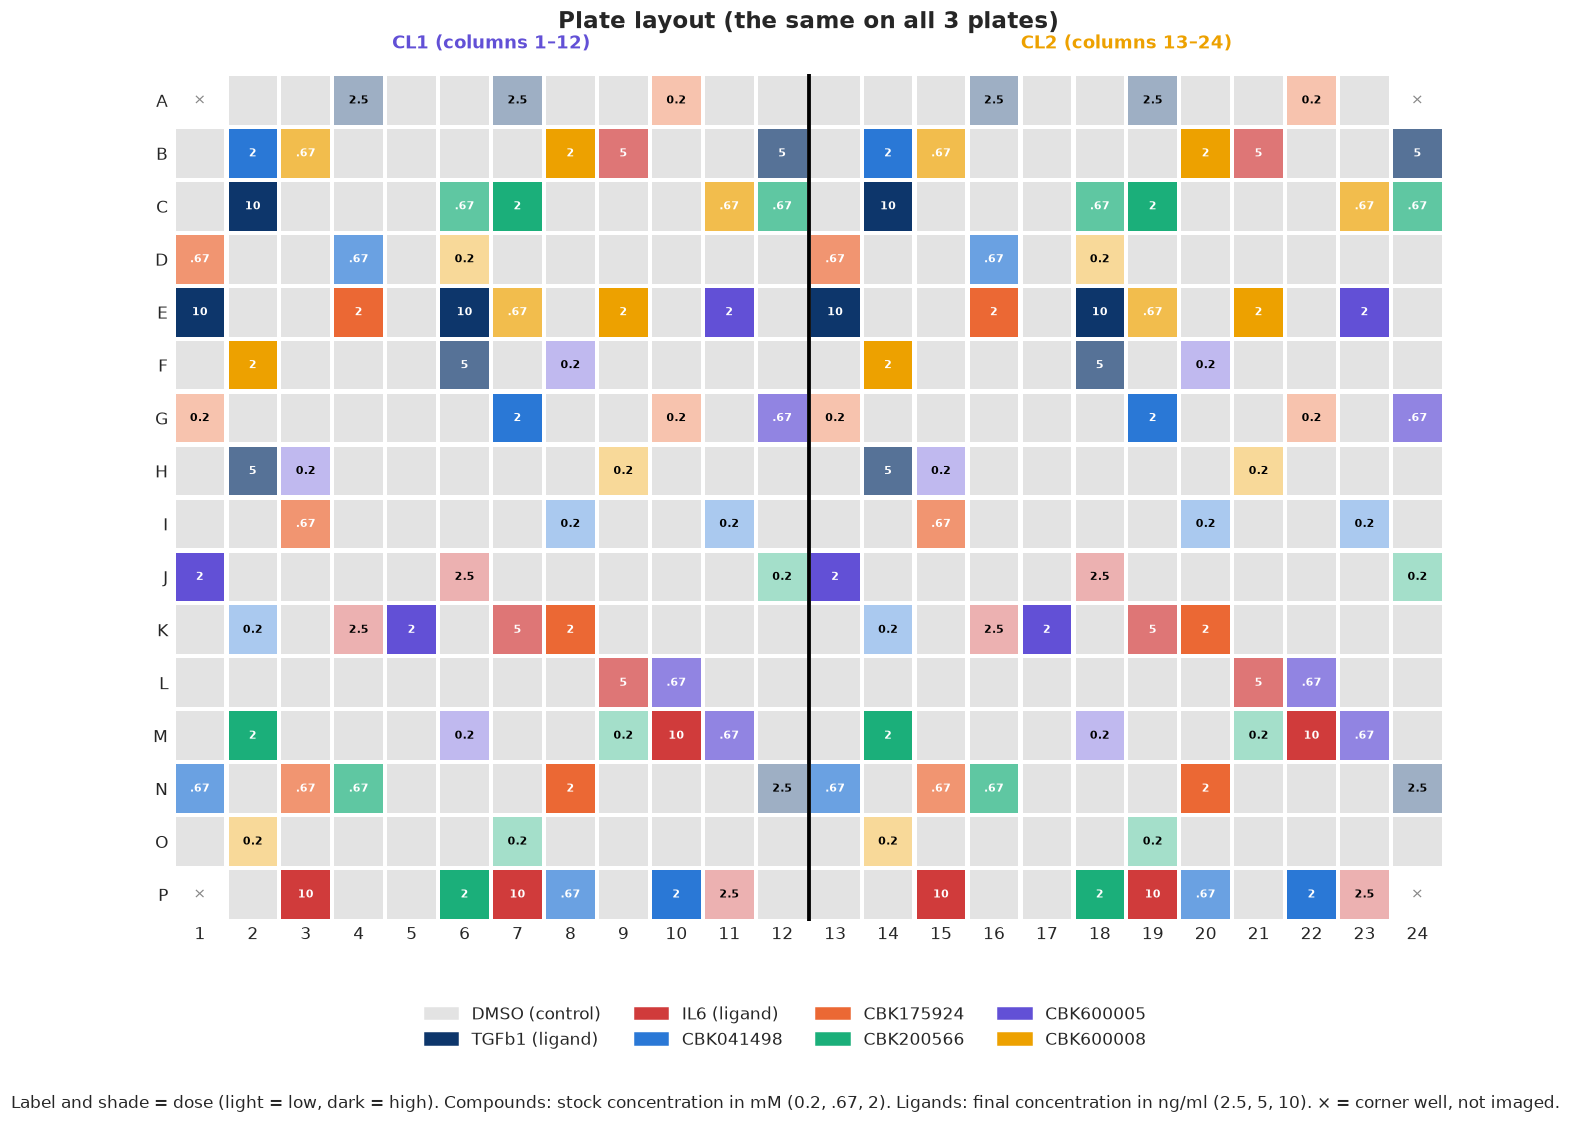

In [6]:
# figure: the plate layout, one square per well; color = agent, shade and label = dose
def dose_shade(color, level):
    # mix the agent color with white: light for the low dose, full color for the high dose
    rgb = np.array(mcolors.to_rgb(color))
    return tuple(rgb + (1 - rgb) * [0.6, 0.3, 0.0][level])


dose_short = {"0.2": "0.2", "0.67": ".67", "2.0": "2", "L": "2.5", "M": "5", "H": "10"}
fig, ax = plt.subplots(figsize=(17, 10))
for w in layout.iter_rows(named=True):
    agent = w["Metadata_treatment"]
    if agent == "DMSO":
        face, label, ink = agent_colors["DMSO"], "", "black"
    else:
        level = dose_level[w["dose"]]
        face, label, ink = dose_shade(agent_colors[agent], level), dose_short[w["dose"]], "white" if level > 0 else "black"
    ax.add_patch(Rectangle((w["col_idx"] - 0.46, w["row_idx"] - 0.46), 0.92, 0.92, facecolor=face, edgecolor="none"))
    ax.text(w["col_idx"], w["row_idx"], label, ha="center", va="center", fontsize=7.5, color=ink, fontweight="bold")
for r, c in [(0, 0), (0, 23), (15, 0), (15, 23)]:
    ax.text(c, r, "×", ha="center", va="center", fontsize=10, color="#888888")
ax.axvline(11.5, color="black", lw=2.5)
ax.set_xlim(-0.5, n_cols - 0.5)
ax.set_ylim(n_rows - 0.5, -0.5)
ax.set_aspect("equal")
ax.set_xticks(range(n_cols), labels=[str(i) for i in range(1, n_cols + 1)])
ax.set_yticks(range(n_rows), labels=plate_rows)
ax.tick_params(length=0)
for spine in ax.spines.values():
    spine.set_visible(False)
ax.text(5.5, -0.9, "CL1 (columns 1–12)", ha="center", va="bottom", fontsize=12, fontweight="bold", color=line_colors["CL1"])
ax.text(17.5, -0.9, "CL2 (columns 13–24)", ha="center", va="bottom", fontsize=12, fontweight="bold", color=line_colors["CL2"])
handles = [Patch(color=agent_colors["DMSO"], label="DMSO (control)")]
handles += [Patch(color=agent_colors[a], label=f"{a} (ligand)") for a in ["TGFb1", "IL6"]]
handles += [Patch(color=agent_colors[a], label=a) for a in compounds]
fig.legend(handles=handles, loc="lower center", ncols=4, frameon=False, bbox_to_anchor=(0.5, -0.02), fontsize=11)
fig.text(
    0.5, -0.06,
    "Label and shade = dose (light = low, dark = high). Compounds: stock concentration in mM (0.2, .67, 2). "
    "Ligands: final concentration in ng/ml (2.5, 5, 10). × = corner well, not imaged.",
    ha="center", fontsize=11,
)
ax.set_title("Plate layout (the same on all 3 plates)", fontsize=15, pad=30, fontweight="bold")
save_fig(fig, "01_plate-layout_treatments-and-doses")

**Result: PASS.**

- One layout for all 3 plates. The plate map and the ligand file agree with the profiles in every well, and the CL2 half repeats the CL1 half exactly, 12 columns to the right.
- Per cell line and plate: 127 DMSO wells, and 3 wells for each of the 21 treatments (7 agents × 3 doses). Every well received 1,500 nL from the compound plate, so DMSO is the same in all wells. The ligand doses come from different volumes (50, 100 and 200 nL). The 4 corner wells received DMSO but were not imaged.
- The replicate wells are spread over the plate: 30 of the 42 replicate sets (per cell line) use 3 different rows and 34 use 3 different columns, and the closest two wells of a set are a median of 4 wells apart. DMSO wells fill the rest of each half, including 62 of the 100 wells on its outer ring.
- What the layout cannot do: each cell line always sits on the same half, and each treatment always sits in the same wells on all 3 plates. A position effect therefore looks the same on every plate, and cell line and plate half cannot be told apart.

## 3. Imaging

The plates were imaged on a SQUID microscope with a 20× objective: 9 fields of view per well (a 3 × 3 grid, 0.9 mm apart) in 5 channels. The image folders keep the settings of each plate (`parameters.json`) and the position, focus height and time of every image (`coords.jsonl`).

**Pass if:** the 3 plates were imaged with the same settings, and the focus height changes smoothly across the plate.

In [7]:
# microscope settings of each plate, for the 5 fluorescence channels
setting_rows, image_rows = [], []
for plate_dir in sorted(p for p in imaging_dir.iterdir() if p.is_dir()):
    files = plate_dir / "input" / plate_dir.name
    params = json.loads((files / "parameters.json").read_text())
    tp = plate_dir.name.split("_")[3]
    for ch in params["channels_config"]:
        nm = ch["Name"].split()[1]
        if nm in channel_stain:
            setting_rows.append({
                "time_point": tp, "imaging_started": params["timestamp"], "channel": f"{nm} nm", "stain": channel_stain[nm],
                "exposure_ms": ch["ExposureTime"], "gain": round(ch["AnalogGain"], 2), "light_pct": ch["IlluminationIntensity"],
                "focus_offset_um": ch["RelativeZOffsetUM"],
            })
    image_rows.append(pl.read_ndjson(files / "coords.jsonl").with_columns(time_point=pl.lit(tp)))
    print(f"{tp} plate: imaging started {params['timestamp']}, {params['objective']}, {params['microscope_name']}, plate {params['plate_type']}, {len(params['well_list'])} wells")
settings = pl.DataFrame(setting_rows).sort(pl.col("time_point").cast(pl.Enum(plate_order)), "stain")
settings.write_csv(table_dir / "imaging_settings.csv")
stain_order = ["DNA", "RNA", "ER", "AGP", "Mito"]
settings_wide = settings.pivot(on="time_point", index="stain", values=["exposure_ms", "focus_offset_um"]).sort(pl.col("stain").replace_strict({s: i for i, s in enumerate(stain_order)}))
with pl.Config(tbl_width_chars=200, tbl_hide_column_data_types=True, tbl_hide_dataframe_shape=True):
    print(settings_wide)
# settings that differ from the 1h plate
reference = settings.filter(pl.col("time_point") == "1h").drop("time_point", "imaging_started")
changed = []
for tp in plate_order[1:]:
    other = settings.filter(pl.col("time_point") == tp).drop("time_point", "imaging_started")
    for ref, oth in zip(reference.sort("stain").iter_rows(named=True), other.sort("stain").iter_rows(named=True)):
        for key in ["exposure_ms", "gain", "light_pct", "focus_offset_um"]:
            if ref[key] != oth[key]:
                changed.append(f"{tp} plate, {ref['stain']}: {key} {ref[key]:g} -> {oth[key]:g}")
print("settings that differ from the 1h plate:", "; ".join(changed) if changed else "none")

# one row per image: when it was taken (seconds after the plate started) and its focus height
images = pl.concat(image_rows).rename({"well": "Metadata_Well"})
per_well = (
    images.group_by("time_point", "Metadata_Well")
    .agg(
        minutes_after_start=pl.col("ts").min() / 60,
        focus_um=pl.col("z").filter(pl.col("channel").str.contains("405")).median(),
        focus_sd_um=pl.col("z").filter(pl.col("channel").str.contains("405")).std(),
    )
    .with_columns(focus_rel_um=pl.col("focus_um") - pl.col("focus_um").median().over("time_point"))
)
wells = wells.join(per_well, on=["time_point", "Metadata_Well"], how="left", maintain_order="left")
assert wells["minutes_after_start"].null_count() == 0
imaging_summary = (
    images.group_by("time_point")
    .agg(images=pl.len(), fields_of_view=pl.struct("Metadata_Well", "site_x", "site_y").n_unique(), minutes=pl.col("ts").max() / 60)
    .join(wells.group_by("time_point").agg(
        focus_range_um=pl.col("focus_rel_um").max() - pl.col("focus_rel_um").min(),
        median_focus_sd_within_well_um=pl.col("focus_sd_um").median(),
    ), on="time_point")
    .with_columns(seconds_per_well=60 * pl.col("minutes") / 380)
    .sort(pl.col("time_point").cast(pl.Enum(plate_order)))
)
with pl.Config(float_precision=1, tbl_hide_column_data_types=True, tbl_hide_dataframe_shape=True):
    print(imaging_summary)
order = images.filter(pl.col("time_point") == "1h").group_by("Metadata_Well").agg(pl.col("ts").min()).sort("ts")["Metadata_Well"].to_list()
print(f"imaging order (1h plate): {', '.join(order[:4])} … {', '.join(order[20:26])} … {order[-1]}")

1h plate: imaging started 2026-10-03_12.20.40, 20x (Olympus), HCS SQUID: squikon A, plate 384-PE-6057302, 380 wells
4h plate: imaging started 2026-10-05_14.52.02, 20x (Olympus), HCS SQUID: squikon A, plate 384-PE-6057302, 380 wells
24h plate: imaging started 2026-10-06_12.54.35, 20x (Olympus), HCS SQUID: squikon A, plate 384-PE-6057302, 380 wells
┌───────┬────────────────┬────────────────┬─────────────────┬────────────────────┬────────────────────┬─────────────────────┐
│ stain ┆ exposure_ms_1h ┆ exposure_ms_4h ┆ exposure_ms_24h ┆ focus_offset_um_1h ┆ focus_offset_um_4h ┆ focus_offset_um_24h │
╞═══════╪════════════════╪════════════════╪═════════════════╪════════════════════╪════════════════════╪═════════════════════╡
│ DNA   ┆ 5.0            ┆ 5.0            ┆ 5.0             ┆ 0.0                ┆ 0.0                ┆ 0.0                 │
│ RNA   ┆ 7.0            ┆ 7.0            ┆ 7.0             ┆ 0.7                ┆ 0.7                ┆ 0.7                 │
│ ER    ┆ 100.0      

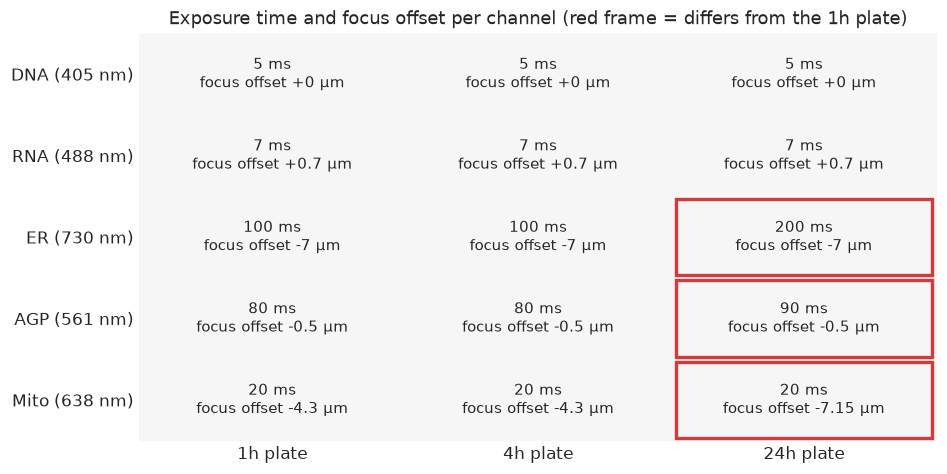

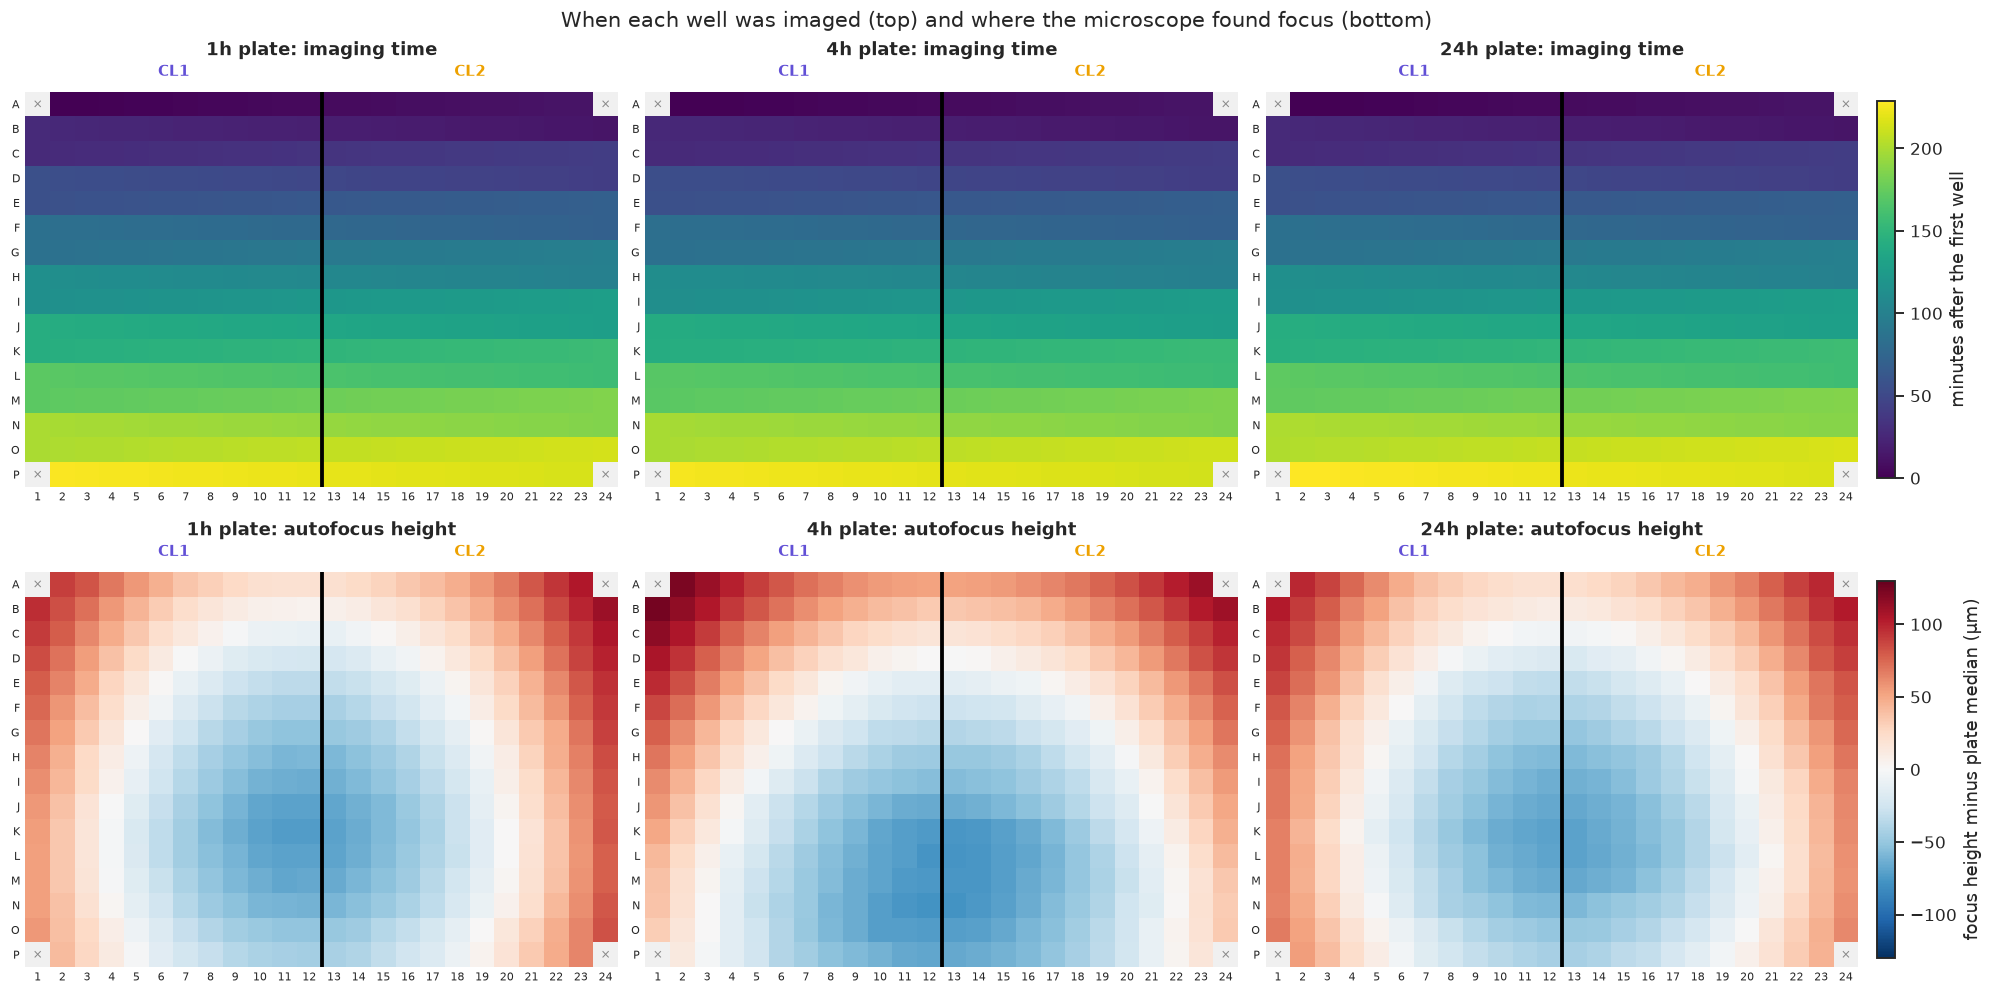

In [8]:
# figure: imaging settings per plate; a red frame marks a setting that differs from the 1h plate
fig, ax = plt.subplots(figsize=(8.5, 4.2), layout="constrained")
exp = np.array([[settings.filter((pl.col("stain") == s) & (pl.col("time_point") == tp))["exposure_ms"][0] for tp in plate_order] for s in stain_order])
off = np.array([[settings.filter((pl.col("stain") == s) & (pl.col("time_point") == tp))["focus_offset_um"][0] for tp in plate_order] for s in stain_order])
ax.imshow(np.zeros_like(exp), cmap=mcolors.ListedColormap(["#f6f6f6"]), aspect="auto")
for i, s in enumerate(stain_order):
    for j, tp in enumerate(plate_order):
        ax.text(j, i, f"{exp[i, j]:g} ms\nfocus offset {off[i, j]:+g} µm", ha="center", va="center", fontsize=10)
        if exp[i, j] != exp[i, 0] or off[i, j] != off[i, 0]:
            ax.add_patch(Rectangle((j - 0.48, i - 0.47), 0.96, 0.94, fill=False, edgecolor="#d03b3b", lw=2.2))
nm_of = {v: k for k, v in channel_stain.items()}
ax.set_xticks(range(len(plate_order)), labels=[f"{tp} plate" for tp in plate_order])
ax.set_yticks(range(len(stain_order)), labels=[f"{s} ({nm_of[s]} nm)" for s in stain_order])
ax.tick_params(length=0)
for spine in ax.spines.values():
    spine.set_visible(False)
ax.set_title("Exposure time and focus offset per channel (red frame = differs from the 1h plate)", fontsize=12)
save_fig(fig, "02_imaging-settings")

# figure: when each well was imaged, and the autofocus height, per plate
time_norm = Normalize(vmin=0, vmax=float(wells["minutes_after_start"].max()))
focus_lim = float(np.ceil(np.abs(wells["focus_rel_um"]).max() / 10) * 10)
fig, axes = plt.subplots(2, 3, figsize=(18, 9), layout="constrained")
for j, tp in enumerate(plate_order):
    plate = wells.filter(pl.col("time_point") == tp)
    im_t = draw_plate(axes[0, j], plate_array(plate, "minutes_after_start"), plt.get_cmap("viridis"), time_norm, f"{tp} plate: imaging time")
    im_z = draw_plate(axes[1, j], plate_array(plate, "focus_rel_um"), div_cmap, TwoSlopeNorm(0, -focus_lim, focus_lim), f"{tp} plate: autofocus height")
fig.colorbar(im_t, ax=axes[0, :], shrink=0.85, pad=0.01, label="minutes after the first well")
fig.colorbar(im_z, ax=axes[1, :], shrink=0.85, pad=0.01, label="focus height minus plate median (µm)")
fig.suptitle("When each well was imaged (top) and where the microscope found focus (bottom)", fontsize=14)
save_fig(fig, "03_plate-maps_imaging-time-and-focus")

**Result: WARN (settings differ on the 24h plate).**

- All plates were imaged on the same microscope with the same objective, 9 fields of view per well, on 3 different days (3, 5 and 6 October 2026).
- The 24h plate used 3 different settings: a longer ER exposure (200 vs 100 ms) and AGP exposure (90 vs 80 ms), and a different Mito focus offset (−7.15 vs −4.3 µm). Time point and these settings cannot be separated, so we compare wells only with the DMSO wells of the same plate.
- Each plate took about 228 minutes (36 s per well), row by row: row A from left to right, row B from right to left, and so on. In Cell Painting the cells are fixed before staining, so the imaging time does not change the treatment time; it could only add technical drift. Section 7b checks this: DMSO wells imaged later do not differ more at 1h and 4h (rho −0.17 to 0.02), and only a little at 24h (0.24 and 0.36), where the late rows M–N are also the low-count rows.
- The focus height changes smoothly across each plate, like a shallow bowl: the edges are up to about 100 µm higher than the centre (range 173–201 µm), and the 9 fields of view of a well differ by a median of only 2.5 µm. Neither the imaging order nor the focus explains the shifted CL1 wells (odd rows of columns 1–6) seen in the other notebooks.

In [9]:
# cell count relative to the DMSO wells of the same plate and cell line
group_keys = ["Metadata_Plate", "cell_line"]
wells = wells.with_columns(
    dmso_median_all=pl.col("n_cells_all").filter(pl.col("is_dmso")).median().over(group_keys),
    dmso_median_qc=pl.col("n_cells_qc").filter(pl.col("is_dmso")).median().over(group_keys),
    dmso_median_pct_pass=pl.col("pct_pass").filter(pl.col("is_dmso")).median().over(group_keys),
).with_columns(
    log2_ratio_all=(pl.col("n_cells_all") / pl.col("dmso_median_all")).log(2),
    log2_ratio_qc=(pl.col("n_cells_qc") / pl.col("dmso_median_qc")).log(2),
    delta_pct_pass=pl.col("pct_pass") - pl.col("dmso_median_pct_pass"),
)

## 4. Cell counts on the plates

Each square is one well, drawn where it sits on the plate. The black line splits the CL1 half (columns 1–12) from the CL2 half (columns 13–24). The color scale is shared by the three plates, so growth over time shows as darker plates.

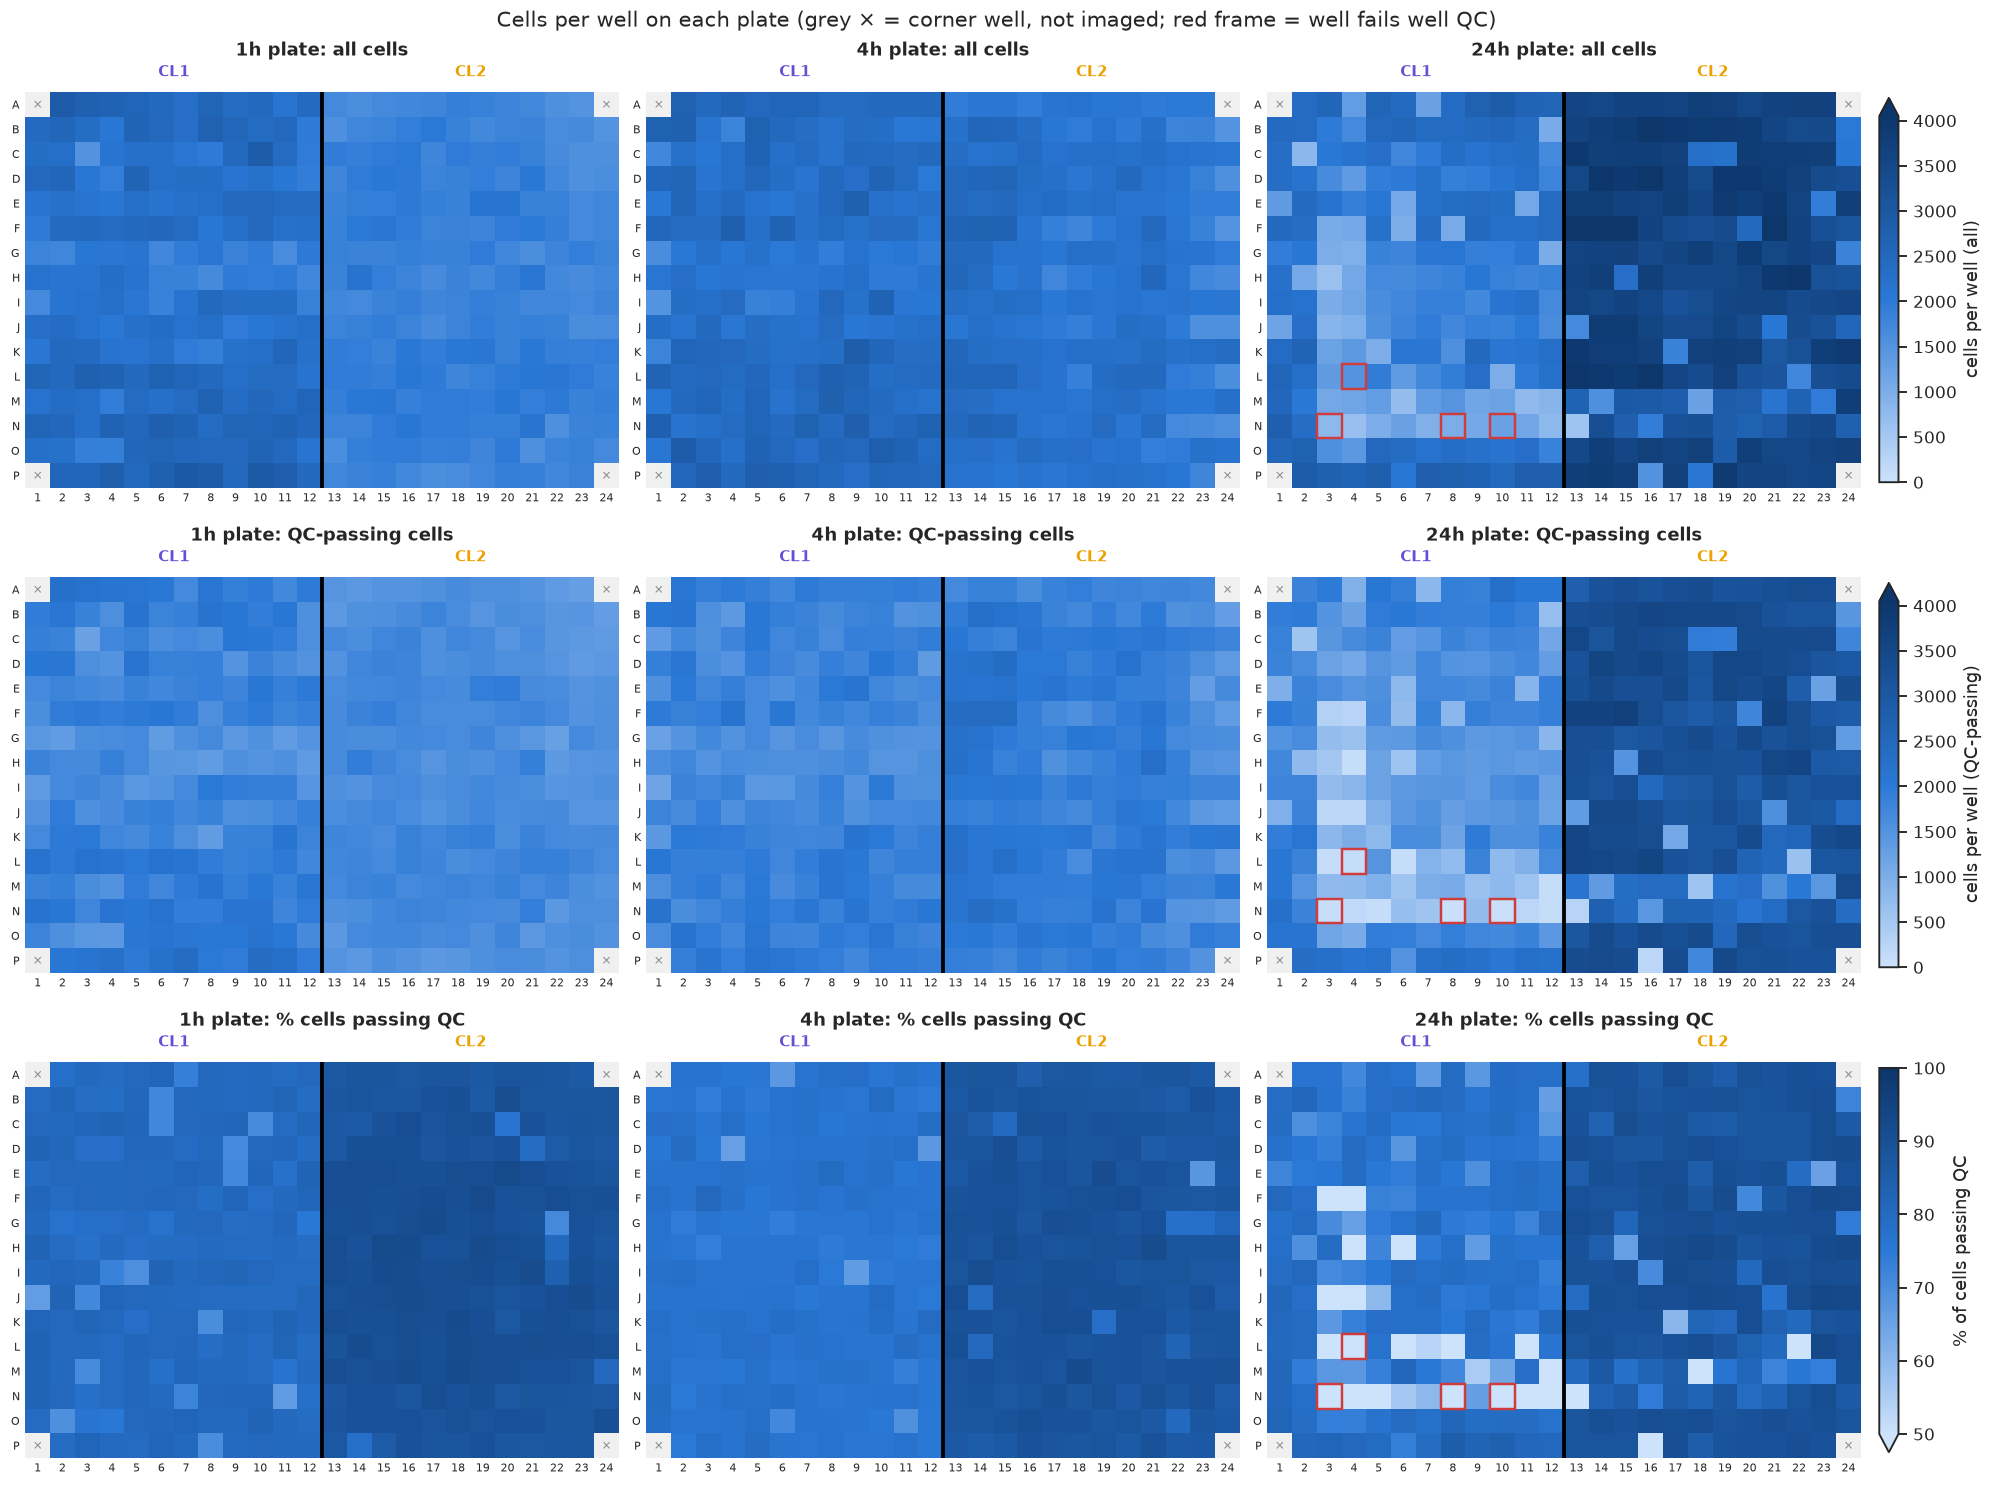

In [10]:
plates = {tp: wells.filter(pl.col("time_point") == tp) for tp in plate_order}
failed = {tp: plate_array(plates[tp].with_columns(f=(~pl.col("profile_ok")).cast(pl.Float64)), "f") == 1 for tp in plate_order}
count_norm = Normalize(vmin=0, vmax=float(np.percentile(wells["n_cells_all"], 99.5)))
# most wells pass 70-95%, so the % scale starts at 50 to show the differences (lower wells get the lightest color)
pass_norm = Normalize(vmin=50, vmax=100)

map_rows = [
    ("n_cells_all", "all cells", count_norm, "cells per well (all)"),
    ("n_cells_qc", "QC-passing cells", count_norm, "cells per well (QC-passing)"),
    ("pct_pass", "% cells passing QC", pass_norm, "% of cells passing QC"),
]
fig, axes = plt.subplots(3, 3, figsize=(18, 13.5), layout="constrained")
for i, (value, label, norm, cbar_label) in enumerate(map_rows):
    for j, tp in enumerate(plate_order):
        im = draw_plate(axes[i, j], plate_array(plates[tp], value), seq_cmap, norm, f"{tp} plate: {label}", flagged=failed[tp])
    fig.colorbar(im, ax=axes[i, :], shrink=0.85, pad=0.01, label=cbar_label, extend="min" if value == "pct_pass" else "max")
fig.suptitle("Cells per well on each plate (grey × = corner well, not imaged; red frame = well fails well QC)", fontsize=14)
save_fig(fig, "04_plate-maps_cell-count")

Raw counts mix two things: the cell lines grow differently, and wells differ within a plate. To see only the second, the next map shows each well relative to the DMSO wells of its own plate and cell line (log2 ratio, all cells). Black dots mark treated wells; wells without a dot are DMSO.

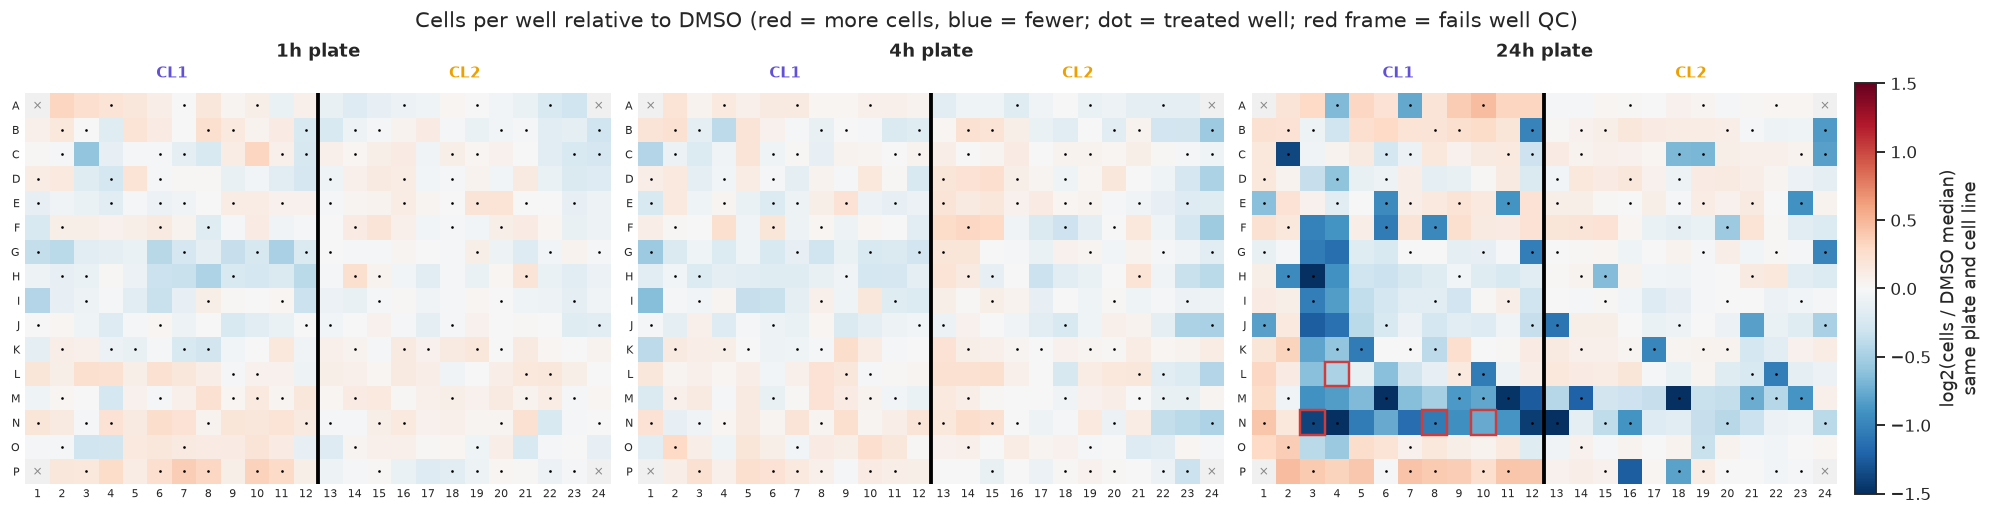

In [11]:
ratio_lim = float(np.ceil(np.percentile(np.abs(wells["log2_ratio_all"]), 99.5) * 4) / 4)
ratio_norm = TwoSlopeNorm(vcenter=0, vmin=-ratio_lim, vmax=ratio_lim)
fig, axes = plt.subplots(1, 3, figsize=(18, 4.8), layout="constrained")
for j, tp in enumerate(plate_order):
    treated = plate_array(plates[tp].with_columns(t=(~pl.col("is_dmso")).cast(pl.Float64)), "t") == 1
    im = draw_plate(axes[j], plate_array(plates[tp], "log2_ratio_all"), div_cmap, ratio_norm, f"{tp} plate", treated=treated, flagged=failed[tp])
fig.colorbar(im, ax=axes, shrink=0.85, pad=0.01, label="log2(cells / DMSO median)\nsame plate and cell line")
fig.suptitle("Cells per well relative to DMSO (red = more cells, blue = fewer; dot = treated well; red frame = fails well QC)", fontsize=14)
save_fig(fig, "05_plate-maps_log2-ratio-to-dmso")

shape: (6, 8)
┌────────────┬───────────┬───────────┬────────────┬────────────┬───────────┬───────────┬───────────┐
│ time_point ┆ cell_line ┆ pct_pass  ┆ pct_fail_i ┆ pct_fail_p ┆ median_pc ┆ min_pct_p ┆ wells_bel │
│ ---        ┆ ---       ┆ ---       ┆ mage       ┆ rofile     ┆ t_pass_pe ┆ ass_per_w ┆ ow_9_imag │
│ str        ┆ str       ┆ f64       ┆ ---        ┆ ---        ┆ r_well    ┆ ell       ┆ es        │
│            ┆           ┆           ┆ f64        ┆ f64        ┆ ---       ┆ ---       ┆ ---       │
│            ┆           ┆           ┆            ┆            ┆ f64       ┆ f64       ┆ u32       │
╞════════════╪═══════════╪═══════════╪════════════╪════════════╪═══════════╪═══════════╪═══════════╡
│ 1h         ┆ CL1       ┆ 79.490252 ┆ 1.138668   ┆ 19.37108   ┆ 80.305553 ┆ 66.392021 ┆ 20        │
│ 1h         ┆ CL2       ┆ 88.940005 ┆ 0.450013   ┆ 10.609982  ┆ 89.40311  ┆ 70.763187 ┆ 8         │
│ 4h         ┆ CL1       ┆ 76.383204 ┆ 0.37183    ┆ 23.244966  ┆ 76.56877  ┆ 

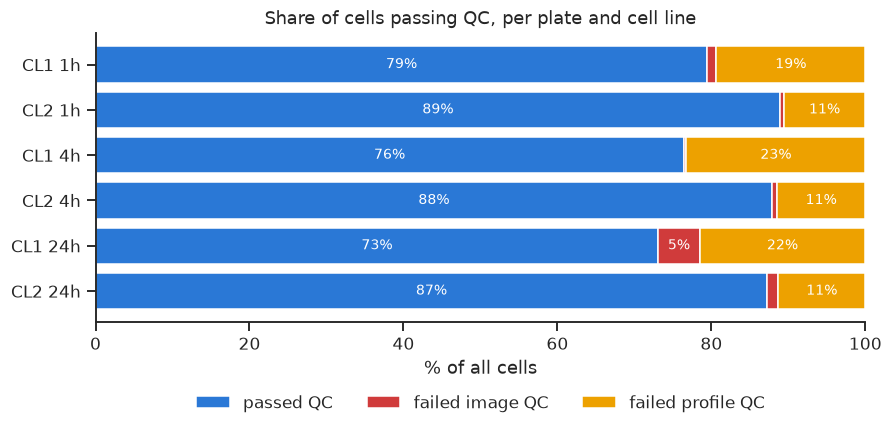

In [12]:
# why cells fail QC: image QC (blurry or saturated image) vs profile QC (segmentation errors)
qc_summary = (
    wells.group_by("time_point", "cell_line")
    .agg(
        all_cells=pl.col("n_cells_all").sum(),
        fail_image=pl.col("n_fail_image").sum(),
        fail_profile=pl.col("n_fail_profile_only").sum(),
        qc_cells=pl.col("n_cells_qc").sum(),
        wells_below_9_images=(pl.col("n_sites_qc") < 9).sum(),
        median_pct_pass_per_well=pl.col("pct_pass").median(),
        min_pct_pass_per_well=pl.col("pct_pass").min(),
    )
    .with_columns(
        pct_fail_image=100 * pl.col("fail_image") / pl.col("all_cells"),
        pct_fail_profile=100 * pl.col("fail_profile") / pl.col("all_cells"),
        pct_pass=100 * pl.col("qc_cells") / pl.col("all_cells"),
    )
    .sort(pl.col("time_point").cast(pl.Enum(plate_order)), "cell_line")
)
qc_summary.write_csv(table_dir / "qc_pass_summary.csv")
print(qc_summary.select("time_point", "cell_line", "pct_pass", "pct_fail_image", "pct_fail_profile", "median_pct_pass_per_well", "min_pct_pass_per_well", "wells_below_9_images"))

fig, ax = plt.subplots(figsize=(8, 3.8), layout="constrained")
labels = [f"{r['cell_line']} {r['time_point']}" for r in qc_summary.iter_rows(named=True)]
y = np.arange(len(labels))
left = np.zeros(len(labels))
for col, name, color in [
    ("pct_pass", "passed QC", "#2a78d6"),
    ("pct_fail_image", "failed image QC", "#d03b3b"),
    ("pct_fail_profile", "failed profile QC", "#eda100"),
]:
    vals = qc_summary[col].to_numpy()
    ax.barh(y, vals, left=left, color=color, label=name)
    for yi, (l, v) in enumerate(zip(left, vals)):
        if v > 4:
            ax.text(l + v / 2, yi, f"{v:.0f}%", ha="center", va="center", fontsize=9, color="white")
    left += vals
ax.set_yticks(y, labels=labels)
ax.invert_yaxis()
ax.set_xlim(0, 100)
ax.set_xlabel("% of all cells")
ax.set_title("Share of cells passing QC, per plate and cell line")
ax.legend(ncols=3, loc="upper center", bbox_to_anchor=(0.5, -0.2), frameon=False)
save_fig(fig, "06_qc-pass-share")

**Result:**

- The 1h and 4h plates are even, with no clear patches.
- On the 24h plate, CL1 has a block of low-count wells in columns 3–4 (rows F–N) and along rows M–N, down to about a third of the DMSO median. The 4 wells that fail well QC (red frames) are all in this area. CL2 is also lower in rows M–N, but less so. DMSO and treated wells in these areas are both low, so this points to seeding or handling, not to the treatments.
- CL1 loses more cells to QC than CL2 on every plate (73–79% pass vs 87–89%), mostly to profile QC (19–23% vs 11%). Image QC matters only for CL1 at 24h (5.4% of cells) and hits the same low-count area, where single wells keep as little as 3% of their cells.

## 5. DMSO control wells

The DMSO wells show how much cell number varies without any treatment. We look at the spread (CV = standard deviation / mean, in %), and at whether wells at the plate edge or in certain rows or columns have fewer cells.

**Pass if:** DMSO wells of one plate and cell line have a CV below about 15%, and no strong edge or row/column pattern.

In [13]:
dmso = wells.filter(pl.col("is_dmso"))
dmso_summary = (
    dmso.unpivot(index=["time_point", "cell_line"], on=["n_cells_all", "n_cells_qc"], variable_name="count", value_name="cells")
    .with_columns(pl.col("count").replace({"n_cells_all": "all cells", "n_cells_qc": "QC-passing cells"}))
    .group_by("count", "time_point", "cell_line")
    .agg(
        n_wells=pl.len(),
        median=pl.col("cells").median(),
        q25=pl.col("cells").quantile(0.25),
        q75=pl.col("cells").quantile(0.75),
        min=pl.col("cells").min(),
        max=pl.col("cells").max(),
        cv_pct=100 * pl.col("cells").std() / pl.col("cells").mean(),
        # robust CV ignores a few outlier wells
        robust_cv_pct=100 * 1.4826 * (pl.col("cells") - pl.col("cells").median()).abs().median() / pl.col("cells").median(),
        wells_below_half_median=(pl.col("cells") < 0.5 * pl.col("cells").median()).sum(),
    )
    .sort("count", pl.col("time_point").cast(pl.Enum(plate_order)), "cell_line")
)
dmso_summary.write_csv(table_dir / "dmso_cell-count_summary.csv")
with pl.Config(tbl_rows=20, tbl_cols=20, float_precision=1):
    print(dmso_summary)

# growth from 1h to 24h, from the DMSO medians
growth = dmso_summary.filter(pl.col("count") == "all cells").pivot(on="time_point", index="cell_line", values="median")
print(growth.with_columns(fold_24h_vs_1h=pl.col("24h") / pl.col("1h")))

shape: (12, 12)
┌────────┬────────┬────────┬────────┬────────┬───────┬───────┬──────┬──────┬───────┬───────┬───────┐
│ count  ┆ time_p ┆ cell_l ┆ n_well ┆ median ┆ q25   ┆ q75   ┆ min  ┆ max  ┆ cv_pc ┆ robus ┆ wells │
│ ---    ┆ oint   ┆ ine    ┆ s      ┆ ---    ┆ ---   ┆ ---   ┆ ---  ┆ ---  ┆ t     ┆ t_cv_ ┆ _belo │
│ str    ┆ ---    ┆ ---    ┆ ---    ┆ f64    ┆ f64   ┆ f64   ┆ i64  ┆ i64  ┆ ---   ┆ pct   ┆ w_hal │
│        ┆ str    ┆ str    ┆ u32    ┆        ┆       ┆       ┆      ┆      ┆ f64   ┆ ---   ┆ f_med │
│        ┆        ┆        ┆        ┆        ┆       ┆       ┆      ┆      ┆       ┆ f64   ┆ ian   │
│        ┆        ┆        ┆        ┆        ┆       ┆       ┆      ┆      ┆       ┆       ┆ ---   │
│        ┆        ┆        ┆        ┆        ┆       ┆       ┆      ┆      ┆       ┆       ┆ u32   │
╞════════╪════════╪════════╪════════╪════════╪═══════╪═══════╪══════╪══════╪═══════╪═══════╪═══════╡
│ QC-pas ┆ 1h     ┆ CL1    ┆ 127    ┆ 1858.0 ┆ 1656. ┆ 2014. ┆ 1247 ┆ 2253 

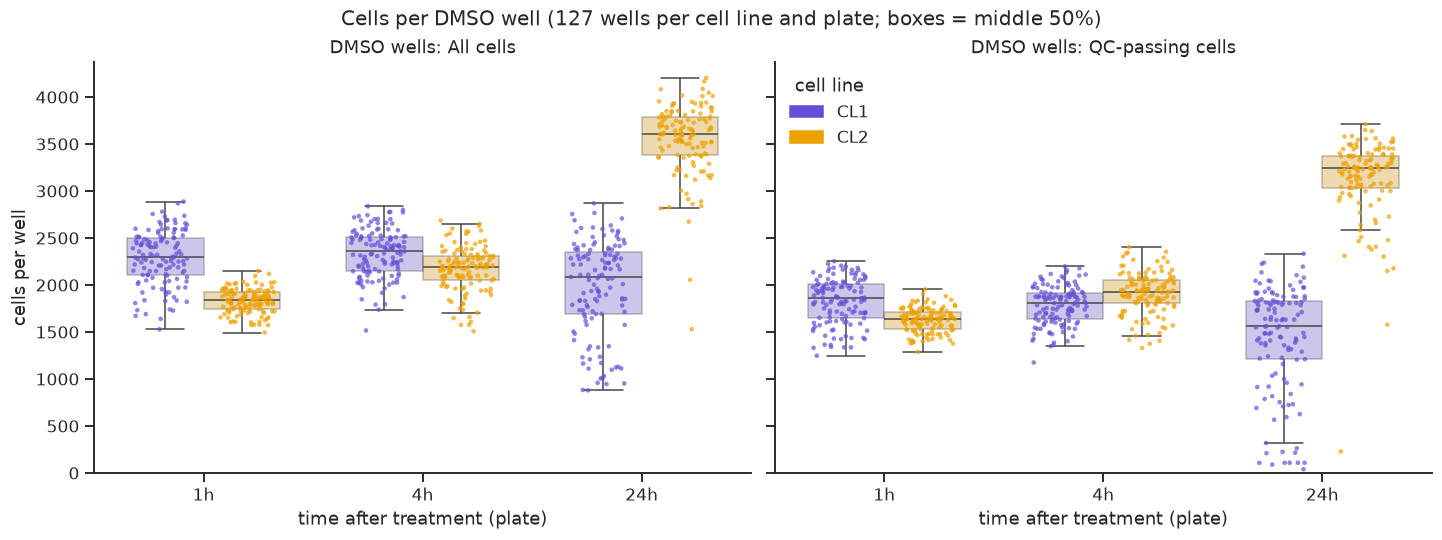

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8), layout="constrained", sharey=True)
plot_df = dmso.select("time_point", "cell_line", "n_cells_all", "n_cells_qc").to_pandas()
for ax, (col, title) in zip(axes, [("n_cells_all", "All cells"), ("n_cells_qc", "QC-passing cells")]):
    sns.boxplot(
        data=plot_df, x="time_point", y=col, hue="cell_line", order=plate_order, hue_order=line_order,
        palette=line_colors, showfliers=False, width=0.7, boxprops={"alpha": 0.35}, ax=ax, legend=False,
    )
    sns.stripplot(
        data=plot_df, x="time_point", y=col, hue="cell_line", order=plate_order, hue_order=line_order,
        palette=line_colors, dodge=True, size=3, alpha=0.7, jitter=0.25, ax=ax, legend=False,
    )
    ax.set_title(f"DMSO wells: {title}")
    ax.set_xlabel("time after treatment (plate)")
    ax.set_ylabel("cells per well")
    ax.set_ylim(bottom=0)
handles = [Patch(color=line_colors[l], label=l) for l in line_order]
axes[1].legend(handles=handles, title="cell line", loc="upper left", frameon=False)
fig.suptitle("Cells per DMSO well (127 wells per cell line and plate; boxes = middle 50%)", fontsize=13)
save_fig(fig, "07_dmso_cell-count-distribution")

In [15]:
# edge wells = the outer ring of the plate (row A or P, column 1 or 24)
dmso = dmso.with_columns(
    position=pl.when(pl.col("Metadata_Row").is_in(["A", "P"]) | pl.col("col_idx").is_in([0, 23]))
    .then(pl.lit("edge"))
    .otherwise(pl.lit("inner"))
)
edge_rows = []
for (tp, line), grp in dmso.group_by("time_point", "cell_line"):
    edge = grp.filter(pl.col("position") == "edge")["log2_ratio_all"].to_numpy()
    inner = grp.filter(pl.col("position") == "inner")["log2_ratio_all"].to_numpy()
    edge_rows.append(
        {
            "time_point": tp, "cell_line": line, "n_edge": len(edge), "n_inner": len(inner),
            "edge_median_pct_of_dmso": 100 * 2 ** np.median(edge),
            "inner_median_pct_of_dmso": 100 * 2 ** np.median(inner),
            "mannwhitney_p": stats.mannwhitneyu(edge, inner).pvalue,
        }
    )
edge_table = pl.DataFrame(edge_rows).sort(pl.col("time_point").cast(pl.Enum(plate_order)), "cell_line")
edge_table.write_csv(table_dir / "dmso_edge-vs-inner.csv")
with pl.Config(float_precision=3):
    print(edge_table)

# row and column trends: median log2 ratio of the DMSO wells in each row / column
row_trend = dmso.group_by("time_point", "cell_line", "row_idx").agg(pl.col("log2_ratio_all").median(), n=pl.len())
col_trend = dmso.group_by("time_point", "cell_line", "col_idx").agg(pl.col("log2_ratio_all").median(), n=pl.len())
# how far the worst row / column sits from DMSO
for name, trend, label in [
    ("row", row_trend, pl.col("row_idx").map_elements(plate_rows.__getitem__, return_dtype=pl.String)),
    ("column", col_trend, (pl.col("col_idx") + 1).cast(pl.String)),
]:
    worst = trend.sort("log2_ratio_all").group_by("time_point", "cell_line", maintain_order=True).first()
    print(f"lowest {name} per plate and cell line (median % of DMSO, n = DMSO wells in it):")
    with pl.Config(float_precision=1):
        print(
            worst.with_columns(pct_of_dmso=100 * 2 ** pl.col("log2_ratio_all"), **{name: label})
            .sort(pl.col("time_point").cast(pl.Enum(plate_order)), "cell_line")
            .select("time_point", "cell_line", name, "pct_of_dmso", "n")
        )

shape: (6, 7)
┌────────────┬───────────┬────────┬─────────┬───────────────────┬──────────────────┬───────────────┐
│ time_point ┆ cell_line ┆ n_edge ┆ n_inner ┆ edge_median_pct_o ┆ inner_median_pct ┆ mannwhitney_p │
│ ---        ┆ ---       ┆ ---    ┆ ---     ┆ f_dmso            ┆ _of_dmso         ┆ ---           │
│ str        ┆ str       ┆ i64    ┆ i64     ┆ ---               ┆ ---              ┆ f64           │
│            ┆           ┆        ┆         ┆ f64               ┆ f64              ┆               │
╞════════════╪═══════════╪════════╪═════════╪═══════════════════╪══════════════════╪═══════════════╡
│ 1h         ┆ CL1       ┆ 22     ┆ 105     ┆ 105.869           ┆ 99.304           ┆ 0.066         │
│ 1h         ┆ CL2       ┆ 22     ┆ 105     ┆ 94.647            ┆ 100.707          ┆ 0.000         │
│ 4h         ┆ CL1       ┆ 22     ┆ 105     ┆ 104.561           ┆ 98.727           ┆ 0.314         │
│ 4h         ┆ CL2       ┆ 22     ┆ 105     ┆ 95.039            ┆ 100.869    

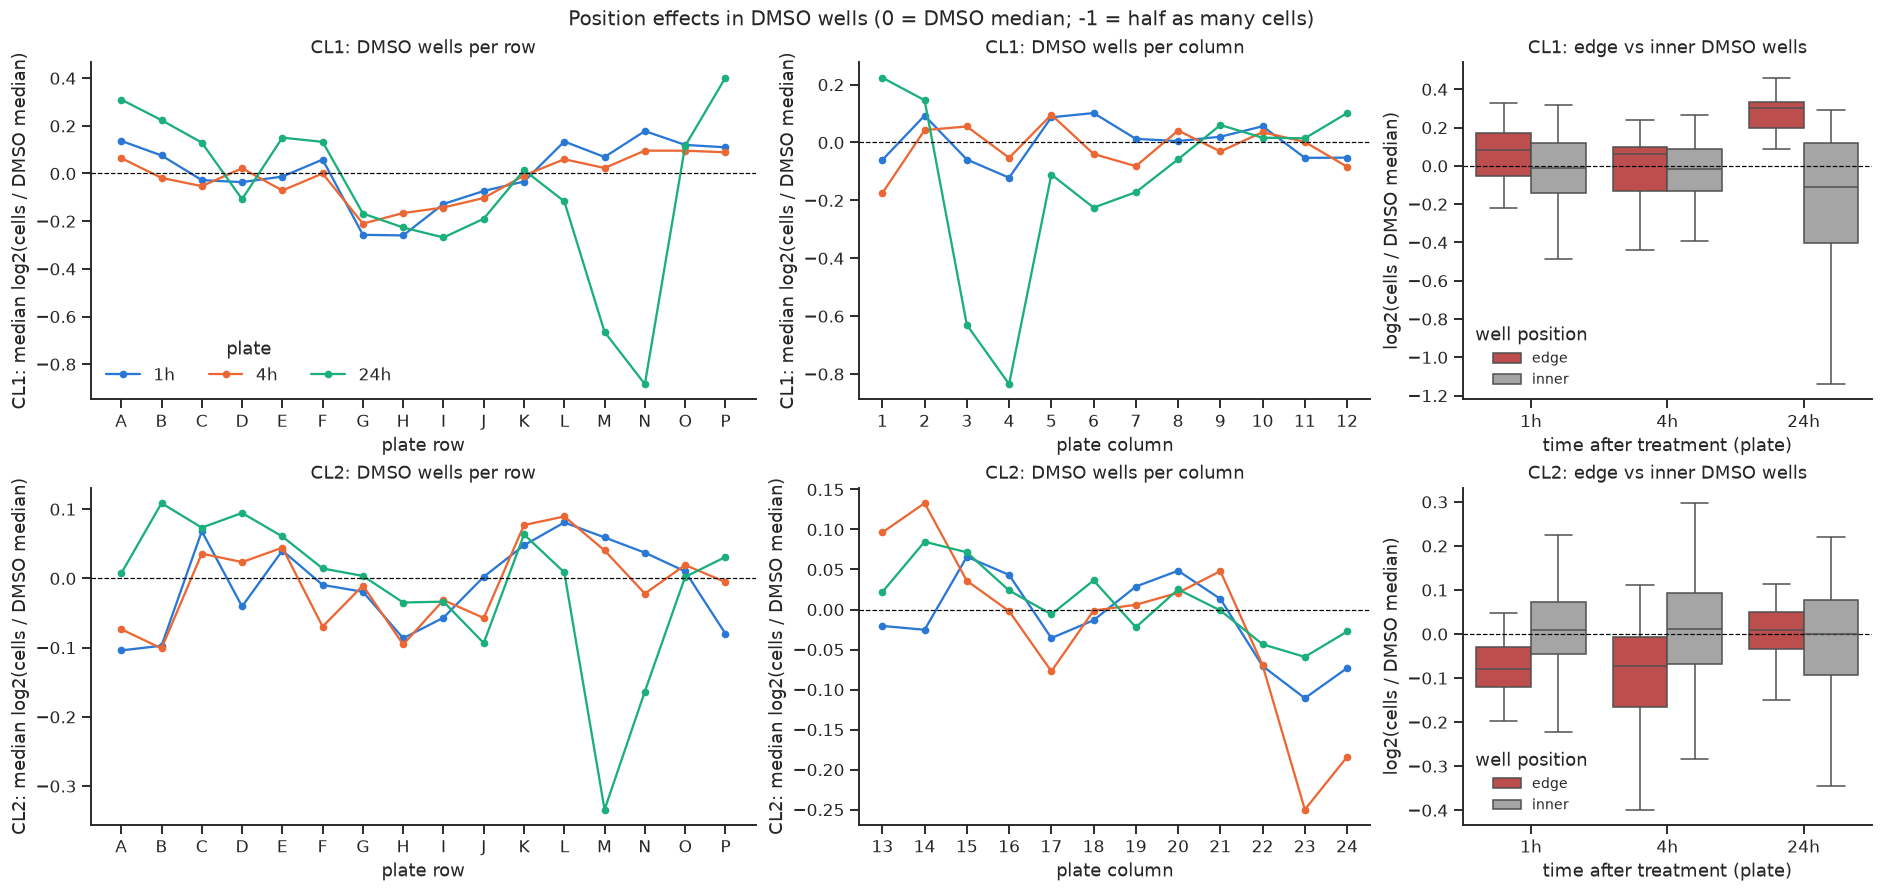

In [16]:
fig, axes = plt.subplots(2, 3, figsize=(17, 8), layout="constrained", gridspec_kw={"width_ratios": [1.3, 1, 0.8]})
for i, line in enumerate(line_order):
    for tp in plate_order:
        r = row_trend.filter((pl.col("cell_line") == line) & (pl.col("time_point") == tp)).sort("row_idx")
        axes[i, 0].plot(r["row_idx"], r["log2_ratio_all"], "-o", ms=4, color=plate_colors[tp], label=tp)
        c = col_trend.filter((pl.col("cell_line") == line) & (pl.col("time_point") == tp)).sort("col_idx")
        axes[i, 1].plot(c["col_idx"] + 1, c["log2_ratio_all"], "-o", ms=4, color=plate_colors[tp], label=tp)
    axes[i, 0].set_xticks(range(n_rows), labels=plate_rows)
    axes[i, 0].set_xlabel("plate row")
    axes[i, 1].set_xticks(range(1, 13) if line == "CL1" else range(13, 25))
    axes[i, 1].set_xlabel("plate column")
    for ax in axes[i, :2]:
        ax.axhline(0, color="black", lw=0.8, ls="--")
        ax.set_ylabel(f"{line}: median log2(cells / DMSO median)")
    axes[i, 0].set_title(f"{line}: DMSO wells per row")
    axes[i, 1].set_title(f"{line}: DMSO wells per column")
    sub = dmso.filter(pl.col("cell_line") == line).select("time_point", "position", "log2_ratio_all").to_pandas()
    sns.boxplot(
        data=sub, x="time_point", y="log2_ratio_all", hue="position", order=plate_order, hue_order=["edge", "inner"],
        palette={"edge": "#d03b3b", "inner": "#a5a5a5"}, showfliers=False, ax=axes[i, 2],
    )
    axes[i, 2].axhline(0, color="black", lw=0.8, ls="--")
    axes[i, 2].set_title(f"{line}: edge vs inner DMSO wells")
    axes[i, 2].set_xlabel("time after treatment (plate)")
    axes[i, 2].set_ylabel("log2(cells / DMSO median)")
    axes[i, 2].legend(title="well position", frameon=False, fontsize=9)
axes[0, 0].legend(title="plate", frameon=False, ncols=3)
fig.suptitle("Position effects in DMSO wells (0 = DMSO median; -1 = half as many cells)", fontsize=13)
save_fig(fig, "08_dmso_position-effects")

**Result:**

- CL1 does not grow: DMSO median 2,300 (1h), 2,356 (4h) and 2,085 (24h) cells per well (0.91× from 1h to 24h). CL2 grows from 1,840 to 2,187 to 3,605 (1.96×).
- The spread passes on the 1h and 4h plates (CV 7–13%) and for CL2 at 24h (11%), but not for CL1 at 24h: CV 25% for all cells, 40% for QC-passing cells, and 8 DMSO wells below half the median. Two of its DMSO wells (L04, N10) have under 100 QC-passing cells and fail well QC.
- CL1 at 24h: DMSO wells in row N have 54% and in column 4 have 56% of the median count. Here edge wells have *more* cells than inner wells (123% vs 92%, p < 0.001), because the low area is inside the plate. This is not a classic edge effect.
- Elsewhere the position effects are small: CL2 edge wells at 1h and 4h have slightly fewer cells (95% vs 101%, p ≤ 0.001). Except for the 24h plate (CL2 row M: 79%), no row or column falls below 83% of the median.

## 6. Do treatments change cell number?

For each treatment we take the median log2 ratio of its 3 replicate wells (the median, so one odd well cannot drive the result). To decide whether this is more than chance, we compare it with 100,000 random sets of 3 DMSO wells from the same plate and cell line: the p-value is the share of random DMSO sets that are at least as far from the DMSO center. We correct for testing 126 treatment × plate × cell line combinations with the Benjamini–Hochberg false discovery rate (FDR). We use all cells, because cells that fail QC are still cells in the well.

**Pass if:** the positive control TGFb1 and the compounds give consistent changes across the 3 replicate wells.

In [17]:
def random_dmso_sets(dmso_values, stat, n_draws=n_null_draws, size=3):
    """Statistic of many random sets of `size` DMSO wells (sampling without replacement)."""
    picks = np.argsort(rng.random((n_draws, len(dmso_values))), axis=1)[:, :size]
    return stat(dmso_values[picks], axis=1)


def bh_fdr(p):
    """Benjamini-Hochberg adjusted p-values."""
    return stats.false_discovery_control(np.asarray(p))


treated = wells.filter(~pl.col("is_dmso"))
count_rows = []
for (plate, line), grp in wells.group_by("Metadata_Plate", "cell_line", maintain_order=True):
    null_medians = random_dmso_sets(grp.filter(pl.col("is_dmso"))["log2_ratio_all"].to_numpy(), np.median)
    center = np.median(null_medians)
    for (pert,), reps in grp.filter(~pl.col("is_dmso")).group_by("Metadata_Perturbation", maintain_order=True):
        values = reps.sort("Metadata_Well")["log2_ratio_all"].to_numpy()
        obs = np.median(values)
        p = (1 + np.sum(np.abs(null_medians - center) >= abs(obs - center))) / (1 + n_null_draws)
        count_rows.append(
            {
                "Metadata_Plate": plate, "time_point": reps["time_point"][0], "cell_line": line,
                "Metadata_Perturbation": pert, "treatment": reps["Metadata_treatment"][0],
                "well_type": reps["Metadata_well_type"][0], "dose": reps["dose"][0],
                "n_wells": len(values), "median_log2_ratio": obs,
                "replicate_log2_ratios": ", ".join(f"{v:.2f}" for v in values),
                "pct_of_dmso": 100 * 2**obs,
                "median_cells_all": reps["n_cells_all"].median(),
                "dmso_median_cells_all": reps["dmso_median_all"][0],
                "median_pct_pass": reps["pct_pass"].median(),
                "delta_pct_pass": reps["delta_pct_pass"].median(),
                "p_count": p,
            }
        )
treatment_table = (
    pl.DataFrame(count_rows)
    .with_columns(fdr_count=pl.Series(bh_fdr(pl.DataFrame(count_rows)["p_count"])))
    .with_columns(
        count_call=pl.when(pl.col("fdr_count") >= fdr_threshold)
        .then(pl.lit("no change"))
        .when(pl.col("median_log2_ratio") < 0)
        .then(pl.lit("fewer cells"))
        .otherwise(pl.lit("more cells"))
    )
    .sort(
        pl.col("Metadata_Perturbation").cast(pl.Enum(perturbation_order)),
        "cell_line",
        pl.col("time_point").cast(pl.Enum(plate_order)),
    )
)
print(treatment_table.group_by("cell_line", "time_point", "count_call").len().sort("cell_line", pl.col("time_point").cast(pl.Enum(plate_order)), "count_call"))
with pl.Config(tbl_rows=60, tbl_cols=12, float_precision=2, tbl_width_chars=200):
    print(
        treatment_table.filter(pl.col("count_call") != "no change")
        .select("cell_line", "time_point", "Metadata_Perturbation", "replicate_log2_ratios", "pct_of_dmso", "delta_pct_pass", "fdr_count", "count_call")
        .sort("pct_of_dmso")
    )

shape: (8, 4)
┌───────────┬────────────┬─────────────┬─────┐
│ cell_line ┆ time_point ┆ count_call  ┆ len │
│ ---       ┆ ---        ┆ ---         ┆ --- │
│ str       ┆ str        ┆ str         ┆ u32 │
╞═══════════╪════════════╪═════════════╪═════╡
│ CL1       ┆ 1h         ┆ no change   ┆ 21  │
│ CL1       ┆ 4h         ┆ no change   ┆ 21  │
│ CL1       ┆ 24h        ┆ fewer cells ┆ 1   │
│ CL1       ┆ 24h        ┆ no change   ┆ 20  │
│ CL2       ┆ 1h         ┆ no change   ┆ 21  │
│ CL2       ┆ 4h         ┆ no change   ┆ 21  │
│ CL2       ┆ 24h        ┆ fewer cells ┆ 6   │
│ CL2       ┆ 24h        ┆ no change   ┆ 15  │
└───────────┴────────────┴─────────────┴─────┘
shape: (7, 8)
┌───────────┬────────────┬───────────────────────┬───────────────────────┬─────────────┬────────────────┬───────────┬─────────────┐
│ cell_line ┆ time_point ┆ Metadata_Perturbation ┆ replicate_log2_ratios ┆ pct_of_dmso ┆ delta_pct_pass ┆ fdr_count ┆ count_call  │
│ ---       ┆ ---        ┆ ---                   ┆

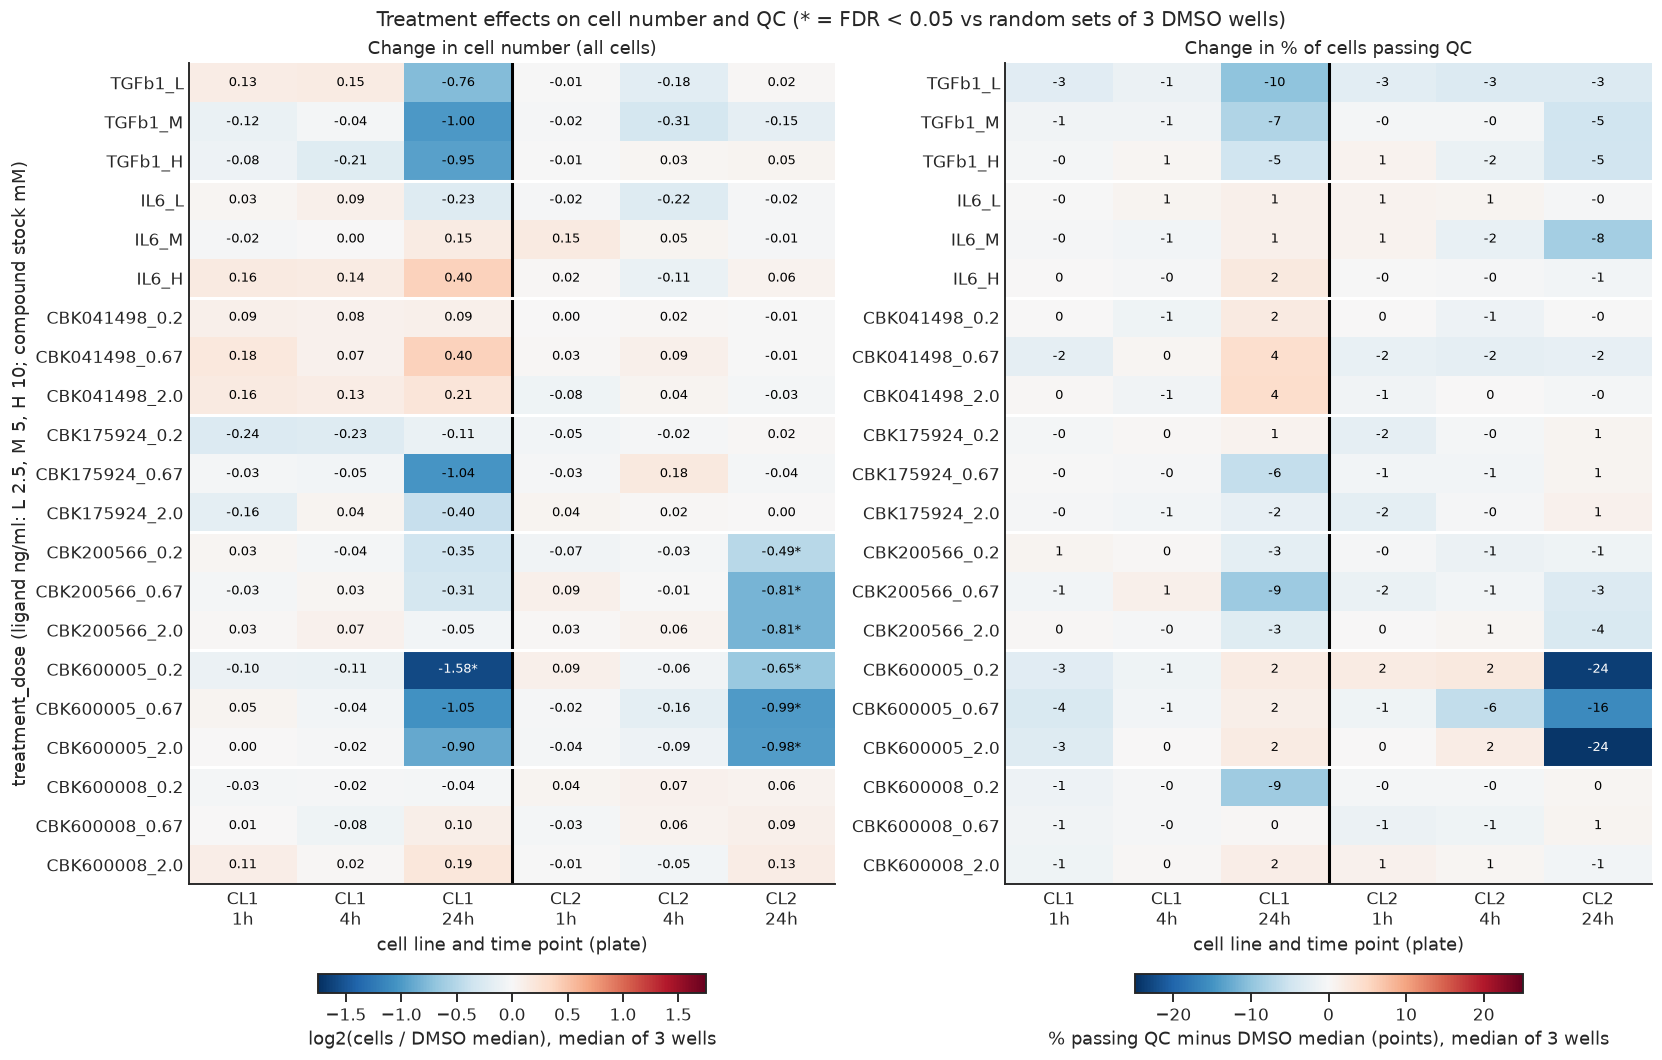

In [18]:
# heatmaps: rows = treatment and dose, columns = cell line and time point
heat_cols = [(line, tp) for line in line_order for tp in plate_order]


def treatment_matrix(value):
    """Pivot one treatment-level value into a perturbation x (cell line, time point) matrix."""
    mat = np.full((len(perturbation_order), len(heat_cols)), np.nan)
    for r in treatment_table.iter_rows(named=True):
        mat[perturbation_order.index(r["Metadata_Perturbation"]), heat_cols.index((r["cell_line"], r["time_point"]))] = r[value]
    return mat


count_mat = treatment_matrix("median_log2_ratio")
fdr_mat = treatment_matrix("fdr_count")
pass_mat = treatment_matrix("delta_pct_pass")
pass_lim = float(np.ceil(np.nanmax(np.abs(pass_mat)) / 5) * 5)
count_lim = float(np.ceil(np.nanmax(np.abs(count_mat)) * 4) / 4)

fig, axes = plt.subplots(1, 2, figsize=(15, 9.5), layout="constrained")
for ax, mat, norm, fmt, label, title in [
    (axes[0], count_mat, TwoSlopeNorm(0, -count_lim, count_lim), "{:.2f}", "log2(cells / DMSO median), median of 3 wells", "Change in cell number (all cells)"),
    (axes[1], pass_mat, TwoSlopeNorm(0, -pass_lim, pass_lim), "{:.0f}", "% passing QC minus DMSO median (points), median of 3 wells", "Change in % of cells passing QC"),
]:
    im = ax.imshow(mat, cmap=div_cmap, norm=norm, aspect="auto")
    for (r, c), v in np.ndenumerate(mat):
        star = "*" if (mat is count_mat and fdr_mat[r, c] < fdr_threshold) else ""
        ax.text(c, r, fmt.format(v) + star, ha="center", va="center", fontsize=8.5, color="white" if abs(norm(v) - 0.5) > 0.33 else "black")
    ax.set_xticks(range(len(heat_cols)), labels=[f"{line}\n{tp}" for line, tp in heat_cols])
    ax.set_yticks(range(len(perturbation_order)), labels=perturbation_order)
    ax.axvline(2.5, color="black", lw=2)
    for y in [2.5, 5.5, 8.5, 11.5, 14.5, 17.5]:
        ax.axhline(y, color="white", lw=2)
    ax.tick_params(length=0)
    ax.set_xlabel("cell line and time point (plate)")
    ax.set_title(title)
    fig.colorbar(im, ax=ax, shrink=0.6, label=label, location="bottom", pad=0.02)
axes[0].set_ylabel("treatment_dose (ligand ng/ml: L 2.5, M 5, H 10; compound stock mM)")
fig.suptitle("Treatment effects on cell number and QC (* = FDR < 0.05 vs random sets of 3 DMSO wells)", fontsize=13)
save_fig(fig, "09_treatment_cell-count-heatmap")

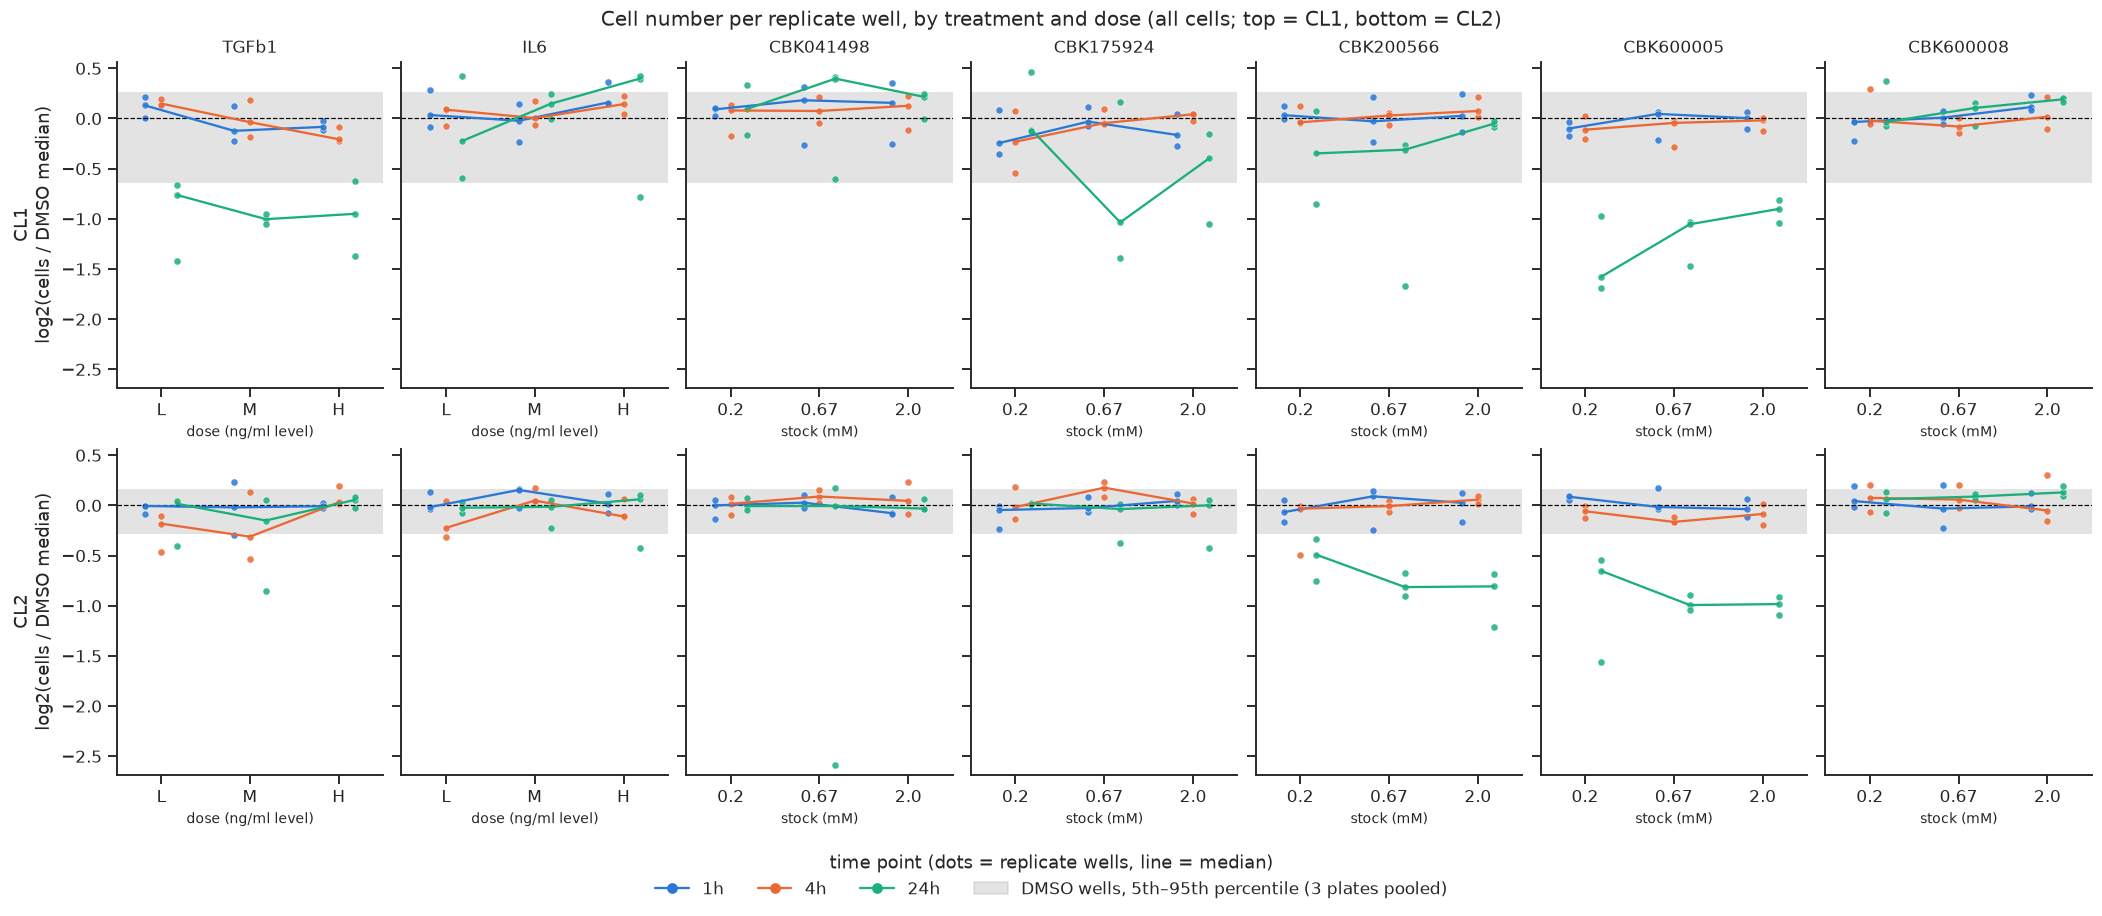

In [19]:
# replicate wells per treatment: x = dose, y = log2 ratio, color = time point
dmso_band = dmso.group_by("cell_line").agg(
    lo=pl.col("log2_ratio_all").quantile(0.05), hi=pl.col("log2_ratio_all").quantile(0.95)
)
fig, axes = plt.subplots(2, len(treatment_order), figsize=(19, 7.5), layout="constrained", sharey=True)
y_lo = float(treated["log2_ratio_all"].min()) - 0.1
y_hi = float(treated["log2_ratio_all"].max()) + 0.1
for i, line in enumerate(line_order):
    band = dmso_band.filter(pl.col("cell_line") == line).row(0, named=True)
    for j, trt in enumerate(treatment_order):
        ax = axes[i, j]
        sub = treated.filter((pl.col("cell_line") == line) & (pl.col("Metadata_treatment") == trt))
        doses = dose_order[sub["Metadata_well_type"][0]]
        ax.axhspan(band["lo"], band["hi"], color="#a5a5a5", alpha=0.3, lw=0)
        ax.axhline(0, color="black", lw=0.8, ls="--")
        for k, tp in enumerate(plate_order):
            s = sub.filter(pl.col("time_point") == tp)
            x = np.array([doses.index(d) for d in s["dose"]]) + (k - 1) * 0.18
            ax.scatter(x, s["log2_ratio_all"], s=22, color=plate_colors[tp], alpha=0.85, edgecolor="white", linewidth=0.4)
            means = s.group_by("dose").agg(pl.col("log2_ratio_all").median())
            means = means.with_columns(x=pl.col("dose").map_elements(doses.index, return_dtype=pl.Int64)).sort("x")
            ax.plot(means["x"] + (k - 1) * 0.18, means["log2_ratio_all"], "-", color=plate_colors[tp], lw=1.5)
        ax.set_xticks(range(3), labels=doses)
        ax.set_xlim(-0.5, 2.5)
        ax.set_ylim(y_lo, y_hi)
        ax.set_title(f"{trt}" if i == 0 else "", fontsize=11)
        ax.set_xlabel("dose (ng/ml level)" if trt in ["TGFb1", "IL6"] else "stock (mM)", fontsize=9)
    axes[i, 0].set_ylabel(f"{line}\nlog2(cells / DMSO median)")
handles = [Line2D([], [], marker="o", color=plate_colors[tp], label=tp) for tp in plate_order]
handles.append(Patch(color="#a5a5a5", alpha=0.3, label="DMSO wells, 5th–95th percentile (3 plates pooled)"))
fig.legend(handles=handles, loc="upper center", ncols=4, bbox_to_anchor=(0.5, -0.01), frameon=False, title="time point (dots = replicate wells, line = median)")
fig.suptitle("Cell number per replicate well, by treatment and dose (all cells; top = CL1, bottom = CL2)", fontsize=13)
save_fig(fig, "10_treatment_cell-count-replicates")

**Result:**

- Clear cell loss occurs only at 24h. 7 of 126 treatment × plate × cell line combinations have significantly fewer cells (FDR < 0.05): **CBK600005** in CL1 (0.2 mM: 33% of DMSO) and in CL2 (64%, 50%, 51% at 0.2, 0.67, 2 mM), and **CBK200566** in CL2 (71%, 57%, 57%). No treatment significantly raises cell number (largest: +32% for IL6_H and CBK041498_0.67 in CL1 at 24h, FDR 0.53).
- In CL1 at 24h, more treatments roughly halve the cell count but do not pass the test, because the DMSO wells of this plate vary so much: CBK600005 at 0.67 and 2 mM (48%, 54%; FDR 0.06, 0.19), CBK175924_0.67 (49%, FDR 0.11), and **TGFb1 at all 3 doses (59%, 50%, 52%; FDR 0.12–0.31)**. 8 of the 9 TGFb1 wells sit outside the low-count area, so this is likely a real TGFb1 effect in CL1, but it needs a cleaner plate to confirm.
- There is no clear dose-response. For CBK600005 in CL1 the lowest dose loses the most cells, and in CL2 the three doses are similar. Only the stock concentrations are known, not the final concentrations in the wells.
- CBK600005 at 24h in CL2 also lowers the share of cells passing QC by 16–24 points (65–74% pass vs 89% in DMSO). The remaining cells often look abnormal, which fits toxicity. All other changes are at most 10 points.

## 7. How cell count relates to the profiles

### 7a. Features that follow cell count in DMSO wells

From here on we use only wells that pass well QC, because a profile made from very few cells is unreliable.

In DMSO wells no treatment is present, so any link between a feature and cell number comes from density (or from what caused the density difference, like seeding or edge effects). For each plate and cell line, we compute the Spearman correlation (rho, rank-based, from -1 to 1) of each feature with the number of cells across the DMSO wells. We call a feature strongly linked to cell count when |rho| ≥ 0.5.

**Pass if:** only a small share of features (say below 10%) strongly follows cell count.

In [20]:
# feature matrix in the same row order as `wells`; clip extreme values (only matters for distances, not ranks)
X_raw = qced.select(feature_cols).to_numpy().astype(np.float64)
profile_ok = wells["profile_ok"].to_numpy()
clipped = np.abs(X_raw[profile_ok]) > clip_limit
print(f"largest |value| in wells passing well QC: {np.nanmax(np.abs(X_raw[profile_ok])):.1f} MADs")
print(f"values clipped to ±{clip_limit}: {100 * clipped.mean():.4f}% ({clipped.sum():,} values in {clipped.any(axis=0).sum()} features)")
X = np.clip(X_raw, -clip_limit, clip_limit)
# rows of `wells` whose profiles are used below (wells passing well QC)
prof = wells.with_row_index("i").filter(pl.col("profile_ok"))
print(f"wells used for profiles: {prof.height:,} of {wells.height:,}; DMSO wells per plate and cell line: "
      f"{prof.filter('is_dmso').group_by('Metadata_Plate', 'cell_line').len()['len'].min()}–{prof.filter('is_dmso').group_by('Metadata_Plate', 'cell_line').len()['len'].max()}")
feature_info = pl.DataFrame(
    {
        "feature": feature_cols,
        "compartment": [f.split("_")[0] for f in feature_cols],
        "category": [f.split("_")[1] for f in feature_cols],
    }
)


def spearman_with(values, matrix):
    """Spearman rho of one vector with every column of a matrix."""
    ranks = stats.rankdata(matrix, axis=0)
    r = stats.rankdata(values)
    ranks = ranks - ranks.mean(axis=0)
    r = r - r.mean()
    denom = np.sqrt((ranks**2).sum(axis=0) * (r**2).sum())
    with np.errstate(invalid="ignore", divide="ignore"):
        return (ranks * r[:, None]).sum(axis=0) / denom


rho_frames = []
is_dmso = wells["is_dmso"].to_numpy()
for tp in plate_order:
    for line in line_order:
        mask = is_dmso & profile_ok & (wells["time_point"] == tp).to_numpy() & (wells["cell_line"] == line).to_numpy()
        rho = spearman_with(wells["log2_ratio_all"].to_numpy()[mask], X[mask])
        rho_frames.append(feature_info.with_columns(time_point=pl.lit(tp), cell_line=pl.lit(line), rho=pl.Series(rho)))
rho_table = pl.concat(rho_frames)
rho_table.write_csv(table_dir / "dmso_feature-vs-cell-count_spearman.csv")

strong_share = (
    rho_table.group_by("time_point", "cell_line")
    .agg(
        n_features=pl.len(),
        n_strong=(pl.col("rho").abs() >= strong_rho).sum(),
        median_abs_rho=pl.col("rho").abs().median(),
        top_feature=pl.col("feature").sort_by(pl.col("rho").abs(), descending=True).first(),
        top_rho=pl.col("rho").sort_by(pl.col("rho").abs(), descending=True).first(),
    )
    .with_columns(pct_strong=100 * pl.col("n_strong") / pl.col("n_features"))
    .sort(pl.col("time_point").cast(pl.Enum(plate_order)), "cell_line")
)
strong_share.write_csv(table_dir / "dmso_share-of-count-linked-features.csv")
with pl.Config(tbl_width_chars=200, fmt_str_lengths=60, float_precision=2):
    print(strong_share)

category_share = (
    rho_table.group_by("category", "time_point", "cell_line")
    .agg(pct_strong=100 * (pl.col("rho").abs() >= strong_rho).mean(), n=pl.len())
)

largest |value| in wells passing well QC: 44.1 MADs
values clipped to ±20: 0.0030% (48 values in 14 features)
wells used for profiles: 1,136 of 1,140; DMSO wells per plate and cell line: 125–127
shape: (6, 8)
┌────────────┬───────────┬────────────┬──────────┬────────────────┬────────────────────────────────────────────────┬─────────┬────────────┐
│ time_point ┆ cell_line ┆ n_features ┆ n_strong ┆ median_abs_rho ┆ top_feature                                    ┆ top_rho ┆ pct_strong │
│ ---        ┆ ---       ┆ ---        ┆ ---      ┆ ---            ┆ ---                                            ┆ ---     ┆ ---        │
│ str        ┆ str       ┆ u32        ┆ u32      ┆ f64            ┆ str                                            ┆ f64     ┆ f64        │
╞════════════╪═══════════╪════════════╪══════════╪════════════════╪════════════════════════════════════════════════╪═════════╪════════════╡
│ 1h         ┆ CL1       ┆ 1399       ┆ 328      ┆ 0.23           ┆ Nuclei_Intensity_StdInt

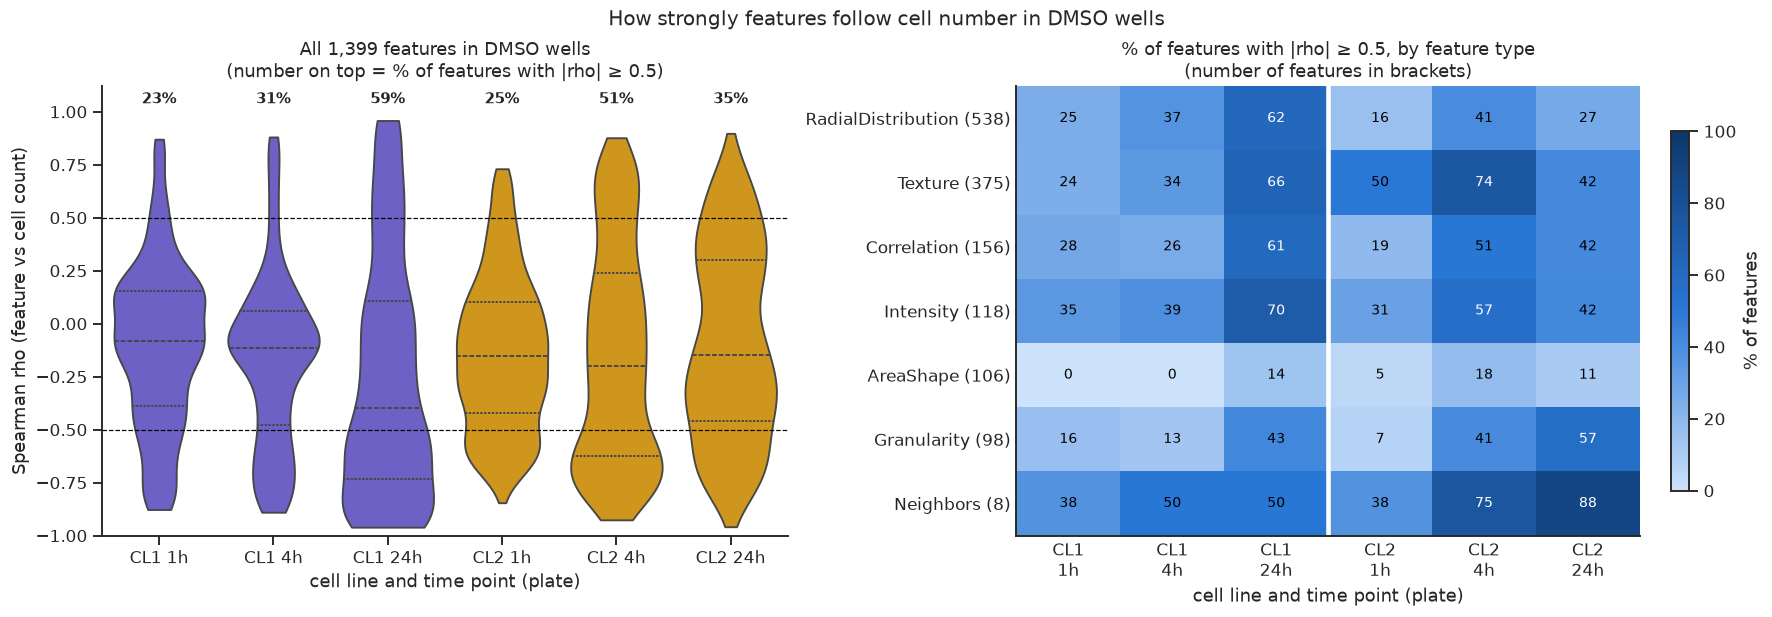

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5.5), layout="constrained", gridspec_kw={"width_ratios": [1.1, 1]})
plot_df = rho_table.with_columns(group=pl.col("cell_line") + " " + pl.col("time_point")).to_pandas()
groups = [f"{line} {tp}" for line in line_order for tp in plate_order]
sns.violinplot(
    data=plot_df, x="group", y="rho", order=groups, hue="cell_line", palette=line_colors,
    inner="quartile", cut=0, density_norm="width", ax=axes[0], legend=False,
)
for y in [-strong_rho, strong_rho]:
    axes[0].axhline(y, color="black", lw=0.8, ls="--")
for k, g in enumerate(groups):
    line, tp = g.split()
    pct = strong_share.filter((pl.col("cell_line") == line) & (pl.col("time_point") == tp))["pct_strong"][0]
    axes[0].text(k, 1.04, f"{pct:.0f}%", ha="center", fontsize=10, fontweight="bold")
axes[0].set_ylim(-1, 1.12)
axes[0].set_xlabel("cell line and time point (plate)")
axes[0].set_ylabel("Spearman rho (feature vs cell count)")
axes[0].set_title(f"All {len(feature_cols):,} features in DMSO wells\n(number on top = % of features with |rho| ≥ {strong_rho})")

categories = category_share.group_by("category").agg(pl.col("n").first()).sort("n", descending=True)
cat_mat = np.full((categories.height, len(groups)), np.nan)
for r in category_share.iter_rows(named=True):
    cat_mat[categories["category"].to_list().index(r["category"]), groups.index(f"{r['cell_line']} {r['time_point']}")] = r["pct_strong"]
im = axes[1].imshow(cat_mat, cmap=seq_cmap, vmin=0, vmax=100, aspect="auto")
for (r, c), v in np.ndenumerate(cat_mat):
    axes[1].text(c, r, f"{v:.0f}", ha="center", va="center", fontsize=9, color="white" if v > 55 else "black")
axes[1].set_xticks(range(len(groups)), labels=[g.replace(" ", "\n") for g in groups])
axes[1].set_yticks(range(categories.height), labels=[f"{c} ({n})" for c, n in categories.iter_rows()])
axes[1].tick_params(length=0)
axes[1].axvline(2.5, color="white", lw=3)
axes[1].set_xlabel("cell line and time point (plate)")
axes[1].set_title(f"% of features with |rho| ≥ {strong_rho}, by feature type\n(number of features in brackets)")
fig.colorbar(im, ax=axes[1], shrink=0.8, label="% of features")
fig.suptitle("How strongly features follow cell number in DMSO wells", fontsize=13)
save_fig(fig, "11_dmso_feature-count-correlation")

**Result:**

- Almost nothing needs clipping: the largest value in wells passing well QC is 44 MADs, and 0.003% of values (48 values in 14 features) are clipped to ±20.
- Many features still follow cell count without any treatment. The share of the 1,399 features with |rho| ≥ 0.5 is 23% (CL1 1h), 31% (CL1 4h), 59% (CL1 24h), 25% (CL2 1h), 51% (CL2 4h) and 35% (CL2 24h). The pass criterion (< 10%) fails on every plate. The share is highest for CL1 at 24h (where cell counts vary most) and CL2 at 4h, which matches the earlier QC finding.
- Neighbor features (how crowded a cell is) follow cell count most (38–88% of 8 features). Texture and intensity come next (66% and 70% for CL1 at 24h; 74% and 57% for CL2 at 4h), and cell shape (AreaShape) least (0–18%).
- The top features are measurements such as `Cells_Correlation_RWC_CorrDNA_CorrER` and `Nuclei_Texture_InfoMeas2_CorrER_5_00_256` (|rho| 0.85–0.96).

### 7b. Is a treatment's profile change linked to its change in cell number?

For each well we measure its **distance from DMSO**: the mean absolute difference over all features between the well's profile and the median DMSO well of the same plate and cell line, in MAD units (features clipped to ±20 MADs first, so a few features with extreme values cannot dominate). We show it as a ratio to the median DMSO well (1 = a typical DMSO well). A treatment's distance is the median of its wells that pass well QC (normally 3), tested against random sets of the same number of DMSO wells (as in section 6). We call a treatment **active** if FDR < 0.05.

**Pass if:** active treatments are not simply the ones that changed cell number.

In [22]:
def distance_from_dmso(matrix, mask_dmso):
    """Mean absolute difference (over features) of each row from the median DMSO row."""
    center = np.median(matrix[mask_dmso], axis=0)
    return np.mean(np.abs(matrix - center), axis=1)


def score_treatments(matrix, label):
    """Distance of every QC-passing well from DMSO, and a test of each treatment's median distance vs random DMSO sets of the same size."""
    dist = np.full(wells.height, np.nan)
    rows = []
    for (plate, line), grp in prof.group_by("Metadata_Plate", "cell_line", maintain_order=True):
        idx = grp["i"].to_numpy()
        grp_dmso = grp["is_dmso"].to_numpy()
        dist[idx] = distance_from_dmso(matrix[idx], grp_dmso)
        dmso_dist = dist[idx][grp_dmso]
        # a treatment with a failed well has 2 wells left, so its null uses sets of 2
        nulls = {}
        for (pert,), reps in grp.filter(~pl.col("is_dmso")).group_by("Metadata_Perturbation", maintain_order=True):
            n = reps.height
            if n not in nulls:
                nulls[n] = random_dmso_sets(dmso_dist, np.median, size=n)
            d = np.median(dist[reps["i"].to_numpy()])
            rows.append(
                {
                    "Metadata_Plate": plate, "cell_line": line, "Metadata_Perturbation": pert,
                    "n_wells_profile": n,
                    f"distance_{label}": d,
                    f"distance_ratio_{label}": d / np.median(dmso_dist),
                    f"p_{label}": (1 + np.sum(nulls[n] >= d)) / (1 + n_null_draws),
                }
            )
    table = pl.DataFrame(rows)
    table = table.with_columns(pl.Series(f"fdr_{label}", bh_fdr(table[f"p_{label}"])))
    return dist, table.with_columns((pl.col(f"fdr_{label}") < fdr_threshold).alias(f"active_{label}"))


well_distance, distance_table = score_treatments(X, "raw")
wells = wells.with_columns(distance_raw=pl.Series(well_distance))
treatment_table = treatment_table.join(distance_table, on=["Metadata_Plate", "cell_line", "Metadata_Perturbation"], how="left")
print("treatments by number of wells with a usable profile:")
print(treatment_table.group_by("n_wells_profile").len().sort("n_wells_profile"))

# in DMSO wells alone: do wells with fewer or more cells sit further from the DMSO center?
dmso_dist_rows = []
for (tp, line), grp in wells.filter(pl.col("is_dmso") & pl.col("profile_ok")).group_by("time_point", "cell_line"):
    rho = stats.spearmanr(grp["log2_ratio_all"].abs().to_numpy(), grp["distance_raw"].to_numpy()).statistic
    dmso_dist_rows.append({"time_point": tp, "cell_line": line, "median_distance": grp["distance_raw"].median(), "rho_abs_log2_ratio_vs_distance": rho})
dmso_distance = pl.DataFrame(dmso_dist_rows).sort(pl.col("time_point").cast(pl.Enum(plate_order)), "cell_line")
with pl.Config(float_precision=2):
    print("DMSO wells: distance from the DMSO center, and its link to |log2 cell-count ratio|")
    print(dmso_distance)

# across treatments: does the distance follow the change in cell number?
print(f"active treatments: {treatment_table['active_raw'].sum()} of {treatment_table['active_raw'].drop_nulls().len()} tested")
print(treatment_table.group_by("count_call", "active_raw").len().sort("count_call", "active_raw"))
link_rows = []
scored = treatment_table.filter(pl.col("distance_ratio_raw").is_not_null())
for key, grp in [(("all", "all"), scored), *scored.group_by("cell_line", "time_point")]:
    rho = stats.spearmanr(grp["median_log2_ratio"].abs().to_numpy(), grp["distance_ratio_raw"].to_numpy()).statistic
    link_rows.append({"cell_line": key[0], "time_point": key[1], "n_treatments": grp.height, "rho_abs_count_change_vs_distance": rho})
link_table = pl.DataFrame(link_rows).sort("cell_line", "time_point")
with pl.Config(float_precision=2):
    print(link_table)

treatments by number of wells with a usable profile:
shape: (2, 2)
┌─────────────────┬─────┐
│ n_wells_profile ┆ len │
│ ---             ┆ --- │
│ i64             ┆ u32 │
╞═════════════════╪═════╡
│ 2               ┆ 2   │
│ 3               ┆ 124 │
└─────────────────┴─────┘
DMSO wells: distance from the DMSO center, and its link to |log2 cell-count ratio|
shape: (6, 4)
┌────────────┬───────────┬─────────────────┬────────────────────────────────┐
│ time_point ┆ cell_line ┆ median_distance ┆ rho_abs_log2_ratio_vs_distance │
│ ---        ┆ ---       ┆ ---             ┆ ---                            │
│ str        ┆ str       ┆ f64             ┆ f64                            │
╞════════════╪═══════════╪═════════════════╪════════════════════════════════╡
│ 1h         ┆ CL1       ┆ 0.11            ┆ 0.33                           │
│ 1h         ┆ CL2       ┆ 0.10            ┆ 0.35                           │
│ 4h         ┆ CL1       ┆ 0.11            ┆ 0.46                           │
│ 4h

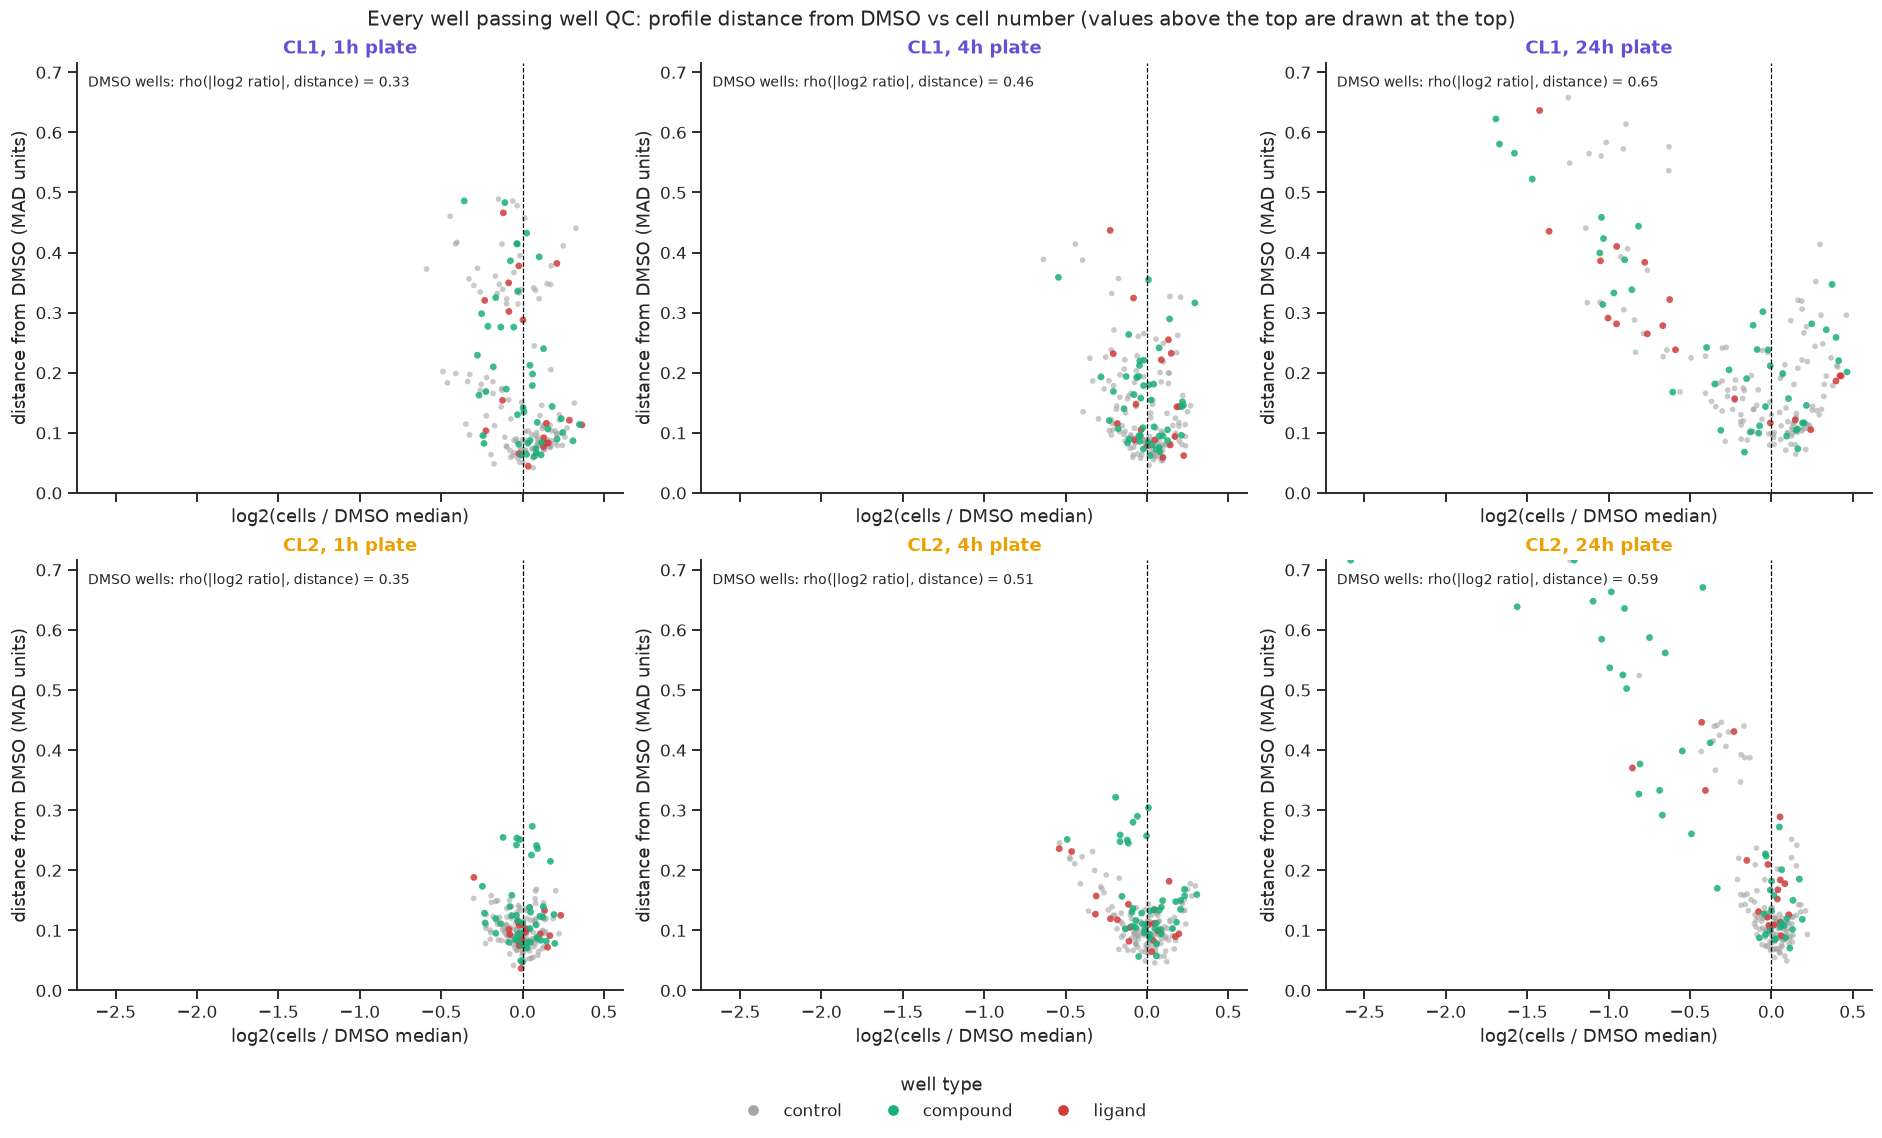

In [23]:
fig, axes = plt.subplots(2, 3, figsize=(17, 9.5), layout="constrained", sharex=True)
d_max = float(np.nanpercentile(wells["distance_raw"].to_numpy(), 99.5)) * 1.1
for i, line in enumerate(line_order):
    for j, tp in enumerate(plate_order):
        ax = axes[i, j]
        sub = wells.filter((pl.col("cell_line") == line) & (pl.col("time_point") == tp) & pl.col("profile_ok"))
        for wt in ["control", "ligand", "compound"]:
            s = sub.filter(pl.col("Metadata_well_type") == wt)
            ax.scatter(s["log2_ratio_all"], s["distance_raw"].clip(upper_bound=d_max), s=14 if wt == "control" else 20,
                       color=well_type_colors[wt], alpha=0.6 if wt == "control" else 0.85, edgecolor="none", label=wt)
        rho = dmso_distance.filter((pl.col("cell_line") == line) & (pl.col("time_point") == tp))["rho_abs_log2_ratio_vs_distance"][0]
        ax.text(0.02, 0.97, f"DMSO wells: rho(|log2 ratio|, distance) = {rho:.2f}", transform=ax.transAxes, va="top", fontsize=9)
        ax.axvline(0, color="black", lw=0.8, ls="--")
        ax.set_ylim(0, d_max)
        ax.set_title(f"{line}, {tp} plate", color=line_colors[line], fontweight="bold")
        ax.set_xlabel("log2(cells / DMSO median)")
        ax.set_ylabel("distance from DMSO (MAD units)")
fig.legend(handles=[Line2D([], [], marker="o", ls="", color=c, label=k) for k, c in well_type_colors.items()],
           title="well type", frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.01), ncols=3)
fig.suptitle("Every well passing well QC: profile distance from DMSO vs cell number (values above the top are drawn at the top)", fontsize=13)
save_fig(fig, "12_wells_distance-vs-cell-count")

In [24]:
# imaging order: do DMSO wells imaged later in the run sit further from the DMSO centre?
order_rows = []
for (tp, line), grp in wells.filter(pl.col("is_dmso") & pl.col("profile_ok")).group_by("time_point", "cell_line"):
    rho = stats.spearmanr(grp["minutes_after_start"], grp["distance_raw"]).statistic
    order_rows.append({"time_point": tp, "cell_line": line, "dmso_wells": grp.height, "rho_imaging_time_vs_distance": round(rho, 2)})
print(pl.DataFrame(order_rows).sort(pl.col("time_point").cast(pl.Enum(plate_order)), "cell_line"))

shape: (6, 4)
┌────────────┬───────────┬────────────┬──────────────────────────────┐
│ time_point ┆ cell_line ┆ dmso_wells ┆ rho_imaging_time_vs_distance │
│ ---        ┆ ---       ┆ ---        ┆ ---                          │
│ str        ┆ str       ┆ i64        ┆ f64                          │
╞════════════╪═══════════╪════════════╪══════════════════════════════╡
│ 1h         ┆ CL1       ┆ 127        ┆ -0.11                        │
│ 1h         ┆ CL2       ┆ 127        ┆ -0.04                        │
│ 4h         ┆ CL1       ┆ 127        ┆ -0.17                        │
│ 4h         ┆ CL2       ┆ 127        ┆ 0.02                         │
│ 24h        ┆ CL1       ┆ 125        ┆ 0.24                         │
│ 24h        ┆ CL2       ┆ 127        ┆ 0.36                         │
└────────────┴───────────┴────────────┴──────────────────────────────┘


**Result:**

- A typical DMSO well differs from the DMSO center by 0.10–0.17 MAD units per feature. DMSO wells whose cell count is further from the median sit further from the center (Spearman rho 0.33–0.35 at 1h, 0.46–0.51 at 4h, 0.65 for CL1 and 0.59 for CL2 at 24h). Cell count is therefore a main source of well-to-well noise.
- 10 of 126 treatments are active: **CBK600005** at all 3 doses in CL2 on every plate (9, FDR < 0.001), and CBK600005_0.2 in CL1 at 24h (FDR 0.046, borderline). No ligand passes, including the positive control TGFb1 (largest: TGFb1_H in CL1 at 1h, 3.5× the DMSO distance, FDR 0.19; at 4h 3.0×, FDR 0.09). Two treatments were tested with 2 wells, because one well failed well QC (CBK175924 0.67 and 2 mM in CL1 at 24h); neither is active.
- Imaging order hardly matters: DMSO wells imaged later in the run are not further from the DMSO centre at 1h and 4h (rho −0.17 to 0.02), and only a little at 24h (0.24 for CL1, 0.36 for CL2), where the rows imaged last (M–N) are also the low-count rows.
- Across treatments, distance and cell-count change are linked only at 24h (rho 0.75 for CL1, 0.57 for CL2), not at 1h (−0.10, −0.16). Over all 126 treatments, rho is 0.26.

### 7c. Do treatment profiles look like "DMSO wells with fewer cells"?

From the DMSO wells we learn the **density pattern**: how each feature changes as the number of cells goes down (a straight-line fit per feature, per plate and cell line). Then, for each treatment, we compare its profile change (median of its wells minus the DMSO median) with this pattern, using the Spearman correlation across all features (rank-based, so a few features with large values cannot dominate). We call this the **low-density likeness**: +1 = the treatment changes features in the same order as a DMSO well with fewer cells, 0 = unrelated, negative = like a well with more cells.

We compare patterns, not sizes, because a straight line learned from DMSO wells (mostly within ±20% of the median count) cannot be trusted at the 50% cell loss of some treatments.

**Pass if:** active treatments that did not change cell number have a low likeness.

In [25]:
# per plate and cell line: slope of each feature against log2 cell-count ratio in DMSO wells
density_rows = []
for (plate, line), grp in prof.group_by("Metadata_Plate", "cell_line", maintain_order=True):
    idx = grp["i"].to_numpy()
    m = grp["is_dmso"].to_numpy()
    z = grp["log2_ratio_all"].to_numpy()[m]
    x_dmso = X[idx][m]
    slope = ((z - z.mean())[:, None] * (x_dmso - x_dmso.mean(axis=0))).sum(axis=0) / ((z - z.mean()) ** 2).sum()
    dmso_center = np.median(x_dmso, axis=0)
    for (pert,), reps in grp.filter(~pl.col("is_dmso")).group_by("Metadata_Perturbation", maintain_order=True):
        shift = np.median(X[reps["i"].to_numpy()], axis=0) - dmso_center
        # negative slope = the change expected when cell number goes down
        density_rows.append(
            {"Metadata_Plate": plate, "cell_line": line, "Metadata_Perturbation": pert, "low_density_likeness": stats.spearmanr(shift, -slope).statistic}
        )
treatment_table = treatment_table.join(pl.DataFrame(density_rows), on=["Metadata_Plate", "cell_line", "Metadata_Perturbation"], how="left")

# possible toxic hits: same rule as mantispy.tl.cytotoxicity (fewer than 70% of DMSO cells and distance above the DMSO median)
treatment_table = treatment_table.with_columns(
    possible_toxicity=((pl.col("pct_of_dmso") < 100 * min_viability) & (pl.col("distance_ratio_raw") > 1)).fill_null(False),
    group=pl.when(pl.col("active_raw") & (pl.col("count_call") == "fewer cells"))
    .then(pl.lit("active, fewer cells"))
    .when(pl.col("active_raw"))
    .then(pl.lit("active, same cell number"))
    .when(pl.col("count_call") == "fewer cells")
    .then(pl.lit("not active, fewer cells"))
    .otherwise(pl.lit("not active, same cell number")),
)
treatment_table.write_csv(table_dir / "treatment_cell-count-and-activity.csv")

print(
    treatment_table.group_by("group")
    .agg(
        n=pl.len(),
        median_low_density_likeness=pl.col("low_density_likeness").median(),
    )
    .sort("group")
)
print(f"possible toxic hits (< {100 * min_viability:.0f}% of DMSO cells and distance above DMSO): {treatment_table['possible_toxicity'].sum()}")
with pl.Config(tbl_rows=60, tbl_cols=12, float_precision=2, tbl_width_chars=220):
    print(
        treatment_table.filter(pl.col("active_raw") | (pl.col("count_call") != "no change") | pl.col("possible_toxicity"))
        .select("cell_line", "time_point", "Metadata_Perturbation", "pct_of_dmso", "count_call", "delta_pct_pass",
                "distance_ratio_raw", "fdr_raw", "active_raw", "low_density_likeness", "possible_toxicity")
        .sort("cell_line", pl.col("time_point").cast(pl.Enum(plate_order)), "distance_ratio_raw", descending=[False, False, True])
    )

shape: (4, 3)
┌──────────────────────────────┬─────┬─────────────────────────────┐
│ group                        ┆ n   ┆ median_low_density_likeness │
│ ---                          ┆ --- ┆ ---                         │
│ str                          ┆ u32 ┆ f64                         │
╞══════════════════════════════╪═════╪═════════════════════════════╡
│ active, fewer cells          ┆ 4   ┆ 0.402877                    │
│ active, same cell number     ┆ 6   ┆ -0.185833                   │
│ not active, fewer cells      ┆ 3   ┆ 0.436835                    │
│ not active, same cell number ┆ 113 ┆ -0.008313                   │
└──────────────────────────────┴─────┴─────────────────────────────┘
possible toxic hits (< 70% of DMSO cells and distance above DMSO): 12
shape: (19, 11)
┌───────────┬────────────┬───────────────────────┬─────────────┬─────────────┬────────────────┬────────────────────┬─────────┬────────────┬──────────────────────┬───────────────────┐
│ cell_line ┆ time_point ┆ 

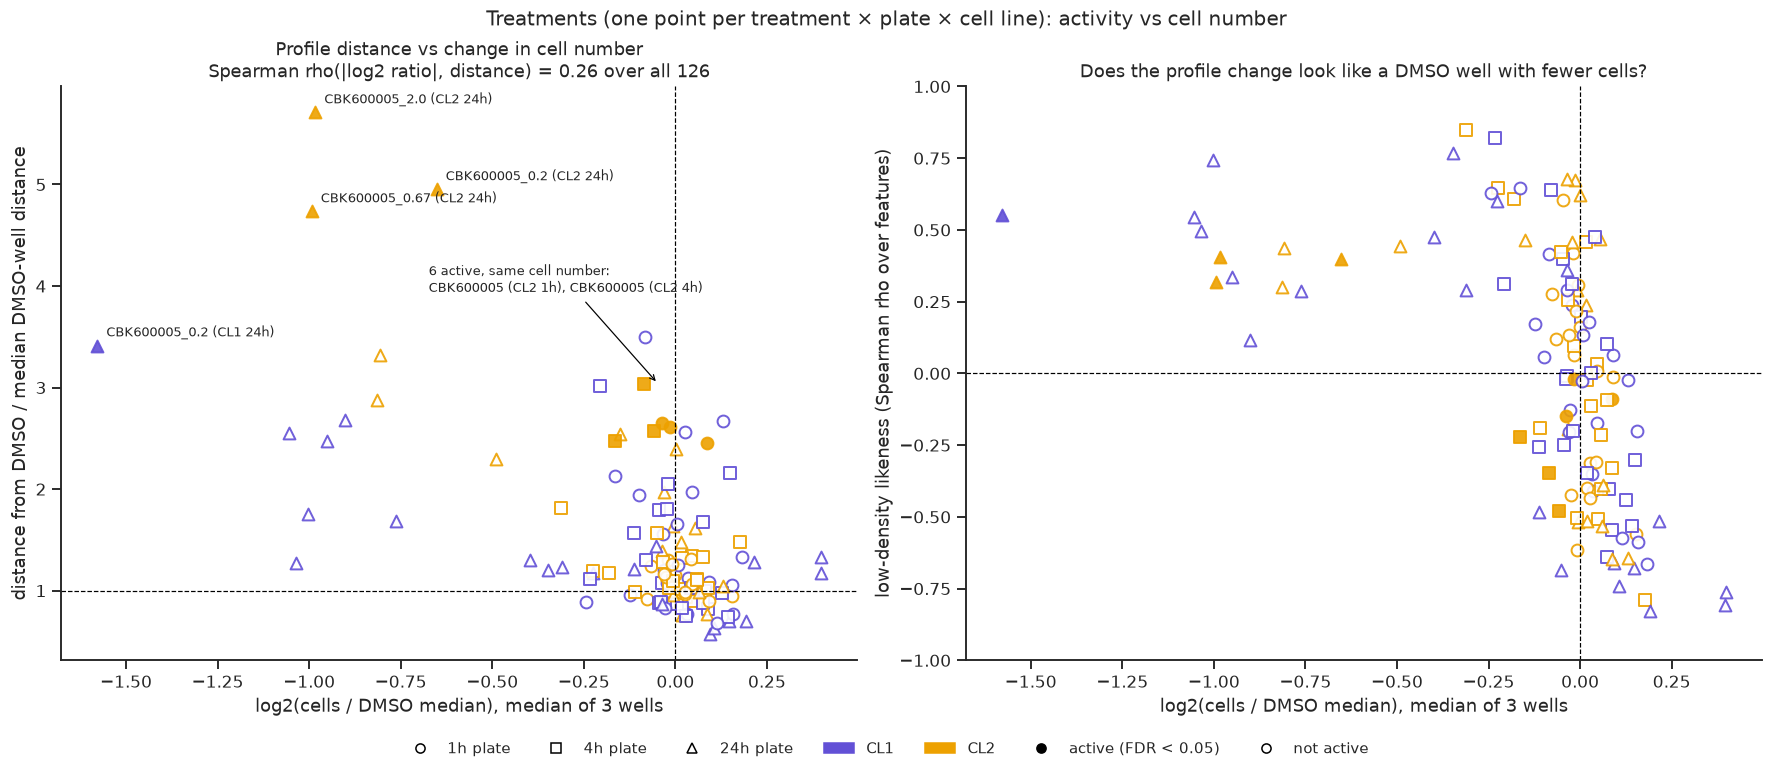

In [26]:
markers = {"1h": "o", "4h": "s", "24h": "^"}
fig, axes = plt.subplots(1, 2, figsize=(16, 6.5), layout="constrained")
for ax, y_col, y_label, title in [
    (axes[0], "distance_ratio_raw", "distance from DMSO / median DMSO-well distance",
     f"Profile distance vs change in cell number\nSpearman rho(|log2 ratio|, distance) = {link_table.filter(pl.col('cell_line') == 'all')['rho_abs_count_change_vs_distance'][0]:.2f} over all {scored.height}"),
    (axes[1], "low_density_likeness", "low-density likeness (Spearman rho over features)",
     "Does the profile change look like a DMSO well with fewer cells?"),
]:
    for r in treatment_table.filter(pl.col(y_col).is_not_null()).iter_rows(named=True):
        ax.scatter(r["median_log2_ratio"], r[y_col], marker=markers[r["time_point"]], s=60,
                   facecolor=line_colors[r["cell_line"]] if r["active_raw"] else "white",
                   edgecolor=line_colors[r["cell_line"]], linewidth=1.3, alpha=0.9)
    ax.axvline(0, color="black", lw=0.8, ls="--")
    ax.axhline(1 if y_col == "distance_ratio_raw" else 0, color="black", lw=0.8, ls="--")
    ax.set_xlabel("log2(cells / DMSO median), median of 3 wells")
    ax.set_ylabel(y_label)
    ax.set_title(title)
# label the active treatments that changed cell number; the others form one cluster near 0
labelled = treatment_table.filter(pl.col("active_raw") & (pl.col("median_log2_ratio") < -0.3)).sort("distance_ratio_raw", descending=True)
for k, r in enumerate(labelled.iter_rows(named=True)):
    axes[0].annotate(f"{r['Metadata_Perturbation']} ({r['cell_line']} {r['time_point']})", (r["median_log2_ratio"], r["distance_ratio_raw"]),
                     xytext=(6, 6), textcoords="offset points", fontsize=8.5)
cluster = treatment_table.filter(pl.col("active_raw") & (pl.col("median_log2_ratio") >= -0.3))
axes[0].annotate(
    f"{cluster.height} active, same cell number:\n" + ", ".join(sorted({f'{p.split('_')[0]} ({l} {t})' for p, l, t in cluster.select('Metadata_Perturbation', 'cell_line', 'time_point').iter_rows()})),
    (float(cluster["median_log2_ratio"].median()), float(cluster["distance_ratio_raw"].max())), xytext=(-150, 60), textcoords="offset points",
    fontsize=8.5, arrowprops={"arrowstyle": "->", "color": "black", "lw": 0.8},
)
axes[1].set_ylim(-1, 1)
handles = [Line2D([], [], marker=markers[tp], ls="", color="black", markerfacecolor="white", label=f"{tp} plate") for tp in plate_order]
handles += [Patch(color=line_colors[l], label=l) for l in line_order]
handles += [Line2D([], [], marker="o", ls="", color="black", markerfacecolor="black", label="active (FDR < 0.05)"),
            Line2D([], [], marker="o", ls="", color="black", markerfacecolor="white", label="not active")]
fig.legend(handles=handles, frameon=False, fontsize=10, loc="upper center", bbox_to_anchor=(0.5, -0.01), ncols=7)
fig.suptitle("Treatments (one point per treatment × plate × cell line): activity vs cell number", fontsize=13)
save_fig(fig, "13_treatments_activity-vs-cell-count")

**Result:**

- Treatments that lowered cell number partly change their profiles like DMSO wells with fewer cells: median likeness 0.40 for the 4 active ones (CBK600005 in CL2 at 24h: 0.32–0.41; in CL1: 0.55) and 0.44 for the 3 that are not active. This is a moderate overlap: part of their "activity" is the cell loss, but most of the feature pattern is not explained by density.
- **CBK600005 in CL2 at 1h and 4h** is active without any change in cell number (89–106% of DMSO), and its pattern does not look like the density pattern (likeness −0.48 to −0.02). This is the clearest effect in the screen that does not come from density. At 24h the same compound also kills or stops cells.
- 12 treatments meet the mantispy cytotoxicity rule (< 70% of DMSO cells and distance above the DMSO median), all at 24h: CBK600005 (both lines, 6), CBK200566 (CL2, 2), TGFb1 (CL1, 3) and CBK175924_0.67 (CL1). Their profiles should be read as partly cell loss.
- The likeness compares patterns, not sizes. For treatments with almost no profile change (most points near 0 cell-count change), the correlation is mostly noise and can be high or low by chance.

## Summary

**Data:** the layout files, the imaging records of the 3 plates, and 1,140 wells (3 plates × 2 cell lines × 190 wells; 127 DMSO wells per cell line per plate) with 2.65 million cells, of which 82.5% pass QC, and 1,399 features. 4 wells (all CL1, 24h plate) fail well QC because they have fewer than 100 QC-passing cells. They are kept in the counts but left out of the profile analyses.

**What we did:** We drew the plate layout and checked it against the profiles, compared the imaging settings, imaging order and focus of the 3 plates, mapped cell counts per well on each plate, measured the spread and position effects in DMSO wells, compared each treatment's cell count with random sets of 3 DMSO wells (FDR < 0.05), and tested how much the profiles follow cell count (feature–count correlation in DMSO wells, distance from DMSO, and likeness to the density pattern).

**Findings:**
- One layout on all 3 plates; CL2 repeats CL1 12 columns to the right. Per cell line and plate: 127 DMSO wells and 21 treatments × 3 wells, spread over the plate. The layout files agree with the profiles in every well.
- The 24h plate was imaged with a longer ER (200 vs 100 ms) and AGP (90 vs 80 ms) exposure and a different Mito focus offset. Each plate took about 3.8 hours to image, row by row; imaging order and focus do not explain the plate patterns.
- CL2 doubles from 1h to 24h (1,840 → 3,605 cells per DMSO well); CL1 does not grow (2,300 → 2,085).
- The 1h and 4h plates are even (DMSO CV 7–13%). On the 24h plate, CL1 has a low-count area (columns 3–4 rows F–N, rows M–N; row N at 54% of the median), with DMSO CV 25%. This area also has the lowest share of cells passing QC and all 4 wells that fail well QC.
- Cell loss is a 24h effect. CBK600005 (both lines, down to 33–64% of DMSO) and CBK200566 (CL2, 57–71%) significantly lower cell number. TGFb1 halves CL1 at 24h at all doses (50–59%) but does not pass FDR on this noisy plate. No treatment raises cell number.
- Cell count drives many features: 23–59% of the 1,399 features have |rho| ≥ 0.5 with cell count in DMSO wells, highest for CL1 at 24h and CL2 at 4h.
- 10 of 126 treatments are active (profile distance, FDR < 0.05), all CBK600005. At 24h, activity follows cell loss (rho 0.75 CL1, 0.57 CL2), and the profiles of count-lowering treatments partly look like low-density DMSO wells (likeness about 0.4). In CL2 at 1h and 4h, CBK600005 is active without cell loss and without a density-like pattern, so this is the clearest density-independent effect. 12 treatments meet the cytotoxicity rule (< 70% cells and distance above DMSO).

**Caveats:**
- Cell line and plate half cannot be separated (CL1 always in columns 1–12), and time point and exposure cannot be separated (24h plate imaged with longer ER/AGP exposures). All comparisons are therefore made within one plate and one cell line.
- Only 3 replicate wells per treatment (2 for CBK175924 0.67 and 2 mM in CL1 at 24h after well QC), and the CL1 24h low-count area makes that plate's tests weak. The one CL1 activity call (CBK600005_0.2) is borderline (FDR 0.046).
- Features were clipped to ±20 MADs before computing distances; only 0.003% of values were clipped.
- Doses are stock concentrations; final well concentrations are unknown.
